---
title: Hidden Markov Model with Control (Part 4)
subtitle: Control a Roomba using Active Inference and RxInfer
author: Kobus Esterhuysen
date: '2024-05-24'
date-modified: last-modified
categories:
  - Bayesian Inference
  - Active Inference
  - RxInfer
  - Julia
image: HMMwithControl.png
format:
  html:
    toc: true
    toc-depth: 4
    toc-expand: true
    toc-title: TOC
    code-fold: false
---

In [ ]:
#| hide
# BASED ON
    # HMMwithControl4_PORT^v3.ipynb
    # HMMwithControl4_PORT^v2.ipynb
    # HMMwithControl3_PORT^v2.ipynb
# DONE
# v1 starts ------------------------------------------------
# add control
# clean for publication
# v3 starts ------------------------------------------------
# v4 starts ------------------------------------------------
# aligned to ActiveInference_Notebook_Standards.md v1.8
#     members in round brackets: s^{(t,n)}, A^{(m)}, B^{(n)}, C^{(m)}, D^{(n)}
#     plain entries V^{[p,τ,0]} and G^{[p,τ]}; the sum over steps is G_Σ
#     realized category plain, one-hot bold; asterisk before the time index
#     index constants roomoccupancy_n, texture_m, light_m, motion_m, destination_n
#     log C given directly; texture and light have log C = 0
#     text conventions, terms, assumptions, symbols table, appendices A and B
#     4.5.6 for expected free energy and action selection
#     plot helpers step_x and step_y, and the default font sizes
#     one run drawn as a stacked figure; comparison averaged over 30 seeds
#     the detail run is unchanged: environment seed 42, random actions from MersenneTwister(7)
#     beliefs and actions of that run match v3; only the reported G shifts by a constant
# TODO

# Hidden Markov Model with Control (Part 4)
## 1 BUSINESS UNDERSTANDING

This is the fourth part of the Hidden Markov Model with Control series, following Parts 1–3. The series adds control to the Hidden Markov Model RxInfer example, towards a scheduling project that uses active inference. Parts 1 and 2 inferred which room the Roomba was in. Part 3 also inferred whether that room was occupied. Terms from those parts are not repeated here.

In this part the agent takes control. At each tick it chooses where the Roomba goes next, so that the Roomba cleans where it does not disturb anyone.

The Roomba keeps its three sensors from Part 3:

- a camera that recognizes the floor surface (hardwood in the bedroom, carpet in the living room, tiles in the bathroom),
- a light sensor that measures brightness (the living room has skylights and is usually bright, the bathroom has no windows and is usually dark, and the bedroom is in between),
- a motion sensor that detects movement, the most direct evidence that a person is present.

As in Part 3, room and occupancy are one state factor, *room occupancy*, with six values: each room, either empty or occupied.

The names of model variables are written in italic lower case, such as *room occupancy*, and their values in double quotes, such as "bedroom-empty". Section 4.1 describes these conventions, and Appendix A gives their motivation.

A goal in active inference is a preference over observations: the agent prefers to observe what it wants to be true. Here it prefers the value "no motion" on the modality *motion*. It cannot see whether a room is occupied, but it can choose actions that it expects to lead to quiet rooms. For each candidate sequence of moves it predicts where the Roomba will end up and what it will observe there, and it scores the sequence by its expected free energy. The score balances reaching preferred observations with reducing uncertainty about *room occupancy*, for example checking a room before settling in it.

**What this part adds.**

- **Actions.** At each tick the Roomba stays where it is or moves towards another room. The transition array has one matrix per action. Occupancy keeps changing as in Part 3.
- **Preferences.** A preference for "no motion", written as $\log\boldsymbol{C}^{(2)}$ on *motion*.
- **An online loop.** The agent and the environment interact tick by tick. The agent observes, updates its belief, chooses an action, and the environment responds.

To keep the focus on control, the agent is given its observation matrices and its transition matrices, rather than learning them as in the previous parts.

**Terms added in this part.**

- **Preference.** The score the agent assigns to the observations it wants to receive. It is the goal, stated over what the agent can sense.
- **Policy.** A sequence of actions the agent considers over its planning horizon.
- **Expected free energy.** The score of a policy: how close the expected observations are to the preferences, together with how uncertain those observations are.
- **Generative process.** The environment that produces the Roomba's state and its sensor readings.
- **Generative model.** The agent's model of that environment, used to infer the state and to choose actions.

**Assumptions.** The transition probabilities, the sensor noise and the strength of the preference are assumed, not measured. The numbers are in 4.3.4 and 4.5.3. The reasons are in Appendix B.

**Structure of the code.** This notebook uses the series protocol. One tick runs execute, then observe, then perceive and plan inside `compute`, then act, then slide.

- `create_envir(...; seed)` returns `(execute, observe, state)`. The environment draws its randomness from `MersenneTwister(seed)`.
    - `execute` carries out the chosen *destination* for one tick: it moves the Roomba and updates *room occupancy*.
    - `observe` returns the observation tuple $\hat{\mathbf{o}}^{(t)}$.
    - `state` returns the true state $\hat{\mathbf{s}}^{\ast(t)}$, for evaluation only.
- `create_agent()` returns `(compute, act, future, slide)`, and also `belief` and `scores` so a run can record the belief and the action probabilities.
    - `compute` infers *room occupancy* $\boldsymbol{s}^{(t,0)}$ and scores the policies.
    - `act` returns the chosen *destination* $\hat{\mathbf{u}}^{(t)}$.
    - `future` returns the predicted beliefs $\boldsymbol{s}^{(\tau,0)}_{\pi^{[p]}}$ under one policy.
    - `slide` moves one tick forward: the posterior becomes the next prior.

As in the previous parts, and as in the active inference literature, $\mathbf{A}$ holds the observation matrices and $\mathbf{B}$ the state transition matrices. That swaps the letters of the original RxInfer example, which uses $A$ for state transitions.

In [1]:
versioninfo() ## Julia version

Julia Version 1.12.7
Commit 6d172b025e4 (2026-08-15 08:05 UTC)
Build Info:
  Official https://julialang.org release
Platform Info:
  OS: Linux (x86_64-linux-gnu)
  CPU: 12 × Intel(R) Core(TM) i7-8700B CPU @ 3.20GHz
  WORD_SIZE: 64
  LLVM: libLLVM-18.1.7 (ORCJIT, skylake)
  GC: Built with stock GC
Threads: 1 default, 1 interactive, 1 GC (on 12 virtual cores)


In [3]:
import Pkg
Pkg.add(Pkg.PackageSpec(;name="RxInfer"))
Pkg.add(Pkg.PackageSpec(;name="Random"))
Pkg.add(Pkg.PackageSpec(;name="Plots"))
Pkg.add(Pkg.PackageSpec(;name="XLSX"))
Pkg.add(Pkg.PackageSpec(;name="DataFrames"))
Pkg.add(Pkg.PackageSpec(;name="BenchmarkTools"))
Pkg.add(Pkg.PackageSpec(;name="Distributions"))
Pkg.add(Pkg.PackageSpec(;name="OffsetArrays"))

using RxInfer, Random, Statistics, LinearAlgebra, BenchmarkTools, Distributions, Plots, XLSX, DataFrames, OffsetArrays

     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/envir

In [4]:
Pkg.status()

Status `~/.julia/environments/v1.12/Project.toml`
  [6e4b80f9] BenchmarkTools v1.8.0
  [a93c6f00] DataFrames v1.8.2
  [31c24e10] Distributions v0.25.132
  [682c06a0] JSON v1.11.0
  [6fe1bfb0] OffsetArrays v1.17.0
  [91a5bcdd] Plots v1.41.7
  [86711068] RxInfer v6.1.0
  [10745b16] Statistics v1.11.5
  [fdbf4ff8] XLSX v0.13.2
  [9a3f8284] Random v1.11.0


## 2 DATA UNDERSTANDING

The data is simulated. Unlike in the previous parts, it is not generated in advance: it arises from the interaction between the agent and the environment. One tick is one step of the Roomba. A run covers $T + 1 = 600$ ticks, $t = 0, \ldots, T$ with $T = 599$. Real sensor logs would come from the Roomba itself; here the generative process stands in for them.

The run records three kinds of one-hot encoded vectors:

- **Observations**, which the agent receives. The observation tuple is $\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{(t,0)}, \hat{\boldsymbol{o}}^{(t,1)}, \hat{\boldsymbol{o}}^{(t,2)}\big)$:
    - *texture*, $\hat{o}^{(t,0)} \in \{\text{hardwood}, \text{carpet}, \text{tiles}\}$
    - *light*, $\hat{o}^{(t,1)} \in \{\text{low}, \text{high}\}$
    - *motion*, $\hat{o}^{(t,2)} \in \{\text{no motion}, \text{motion}\}$
- **Actions**, which the agent chooses, recorded for $t = 0, \ldots, T - 1$. The action tuple is $\hat{\mathbf{u}}^{(t)} = \big(\hat{\boldsymbol{u}}^{(t,0)}\big)$, and *destination* takes the values "bedroom", "livingroom" and "bathroom". Heading for the room the Roomba is already in means staying put. The action chosen at tick $t$ takes effect at tick $t + 1$.
- **True states**, which the agent never sees. The state tuple is $\hat{\mathbf{s}}^{\ast(t)} = \big(\hat{\boldsymbol{s}}^{\ast(t,0)}\big)$. *room occupancy* takes the values "bedroom-empty", "bedroom-occupied", "livingroom-empty", "livingroom-occupied", "bathroom-empty" and "bathroom-occupied".

In each one-hot vector, the component that is 1 marks the value that occurred. The category and the one-hot are the same event: $\hat{o}^{[i]} = \delta_{i\hat{o}}$.

The agent works with the observations only, and with the actions it chose itself. The true states are kept for evaluation: they are how we score disturbance, coverage and tracking.

## 3 DATA PREPARATION

The simulation is used directly; nothing is cleaned or rescaled. What changes in this part is when the data becomes available. At each tick the agent receives only the current observation tuple $\hat{\mathbf{o}}^{(t)}$, updates its belief, and chooses its next action. There is no separate preparation step before inference.

Trajectories are indexed from 0, so index $t$ is time $t$. A run records four of them, each re-indexed with `offset0`:

- `Lôː`, the observations $\hat{\mathbf{o}}^{(0:T)}$, for $t = 0, \ldots, T$
- `Lûː`, the actions $\hat{\mathbf{u}}^{(0:T-1)}$, for $t = 0, \ldots, T - 1$
- `Lsː`, the marginal beliefs $\boldsymbol{s}^{(t,0)}$, for $t = 0, \ldots, T$
- `Lŝˣː`, the true states $\hat{\mathbf{s}}^{\ast(0:T)}$, for evaluation only

`RxInfer` works with ordinary vectors indexed from 1. Data going in is converted with `parent`, and results coming out are re-indexed with `offset0`. In this part that conversion sits inside the agent, at each tick. The agent below does not call `RxInfer`; the boundary stays for later parts.

**Index constants.** One state factor and three modalities, so the constants are numbers rather than functions for a repeated cluster:

- `roomoccupancy_n = 0` for *room occupancy*
- `texture_m = 0`, `light_m = 1`, `motion_m = 2`
- `destination_n = 0` for *destination*

The label vectors, in the same order as those indices, are `state_labels`, `texture_labels`, `light_labels`, `motion_labels` and `action_labels`.

From the joint belief, the belief about the room and the belief about occupancy follow by adding the right entries, as in the evaluation. The helpers below build the 0-based tuples, re-index a trajectory, and draw a step plot on the same edges as a heatmap tile.

In [5]:
## tuple0(x...): build a 0-based tuple (x^{(0)}, ..., x^{(N)}), mirroring the math.
##   - each argument becomes one entry: tuple0(v) wraps v; it never re-indexes v itself
##   - the index range 0:N is derived from the number of arguments
##   - entries may differ in shape, e.g. likelihood matrices for different modalities
## Returns an OffsetVector (mutable), not a Julia Tuple.
tuple0(x...) = OffsetVector(collect(x), 0:length(x)-1)

## offset0(v): re-index an existing vector from 0, e.g. a trajectory over t = 0, ..., T.
## Unlike tuple0, it does not wrap v; it shifts v's own indices.
offset0(v) = OffsetVector(v, 0:length(v)-1)
## ---------- index constants: factor n, modality m, control factor ----------
roomoccupancy_n = 0
texture_m = 0
light_m = 1
motion_m = 2
destination_n = 0

state_labels    = ["bedroom-empty", "bedroom-occupied", "livingroom-empty",
                   "livingroom-occupied", "bathroom-empty", "bathroom-occupied"]
texture_labels  = ["hardwood", "carpet", "tiles"]
light_labels    = ["low", "high"]
motion_labels   = ["no motion", "motion"]
action_labels   = ["bedroom", "livingroom", "bathroom"]

## step_x(n): the n + 1 edges of n tiles, from -0.5 to n - 0.5, so tick t spans t - 0.5 to t + 0.5.
## step_y(v): the series with its last value repeated, for a step plot on those edges.
step_x(n) = collect(range(-0.5, step=1.0, length=n + 1))
step_y(v) = vcat(collect(v), v[end])

## default font sizes: titles 13, axis labels 12, legend 10, ticks 9
default(titlefontsize=13, guidefontsize=12, legendfontsize=10, tickfontsize=9)

**Why `tuple0()` rather than `OffsetVector()` directly?**

1. **It prevents a level mix-up.** With `OffsetVector` it is easy to offset the wrong level:

```julia
    OffsetVector([1.0, 0.0, 0.0], 0:2)    ## the one-hot vector itself, re-indexed 0:2 (wrong level)
    OffsetVector([[1.0, 0.0, 0.0]], 0:0)  ## a tuple containing the one-hot vector (intended)
    tuple0([1.0, 0.0, 0.0])               ## the same as the second line, with no way to get it wrong
```

    The first line is valid code but means something else: the one-hot vector $\hat{\boldsymbol{s}}^{\ast(0,0)}$ itself, now indexed from 0, rather than the tuple $\hat{\mathbf{s}}^{\ast(0)} = \big(\hat{\boldsymbol{s}}^{\ast(0,0)}\big)$. Nothing would complain, and later code that indexes `[0]` would get a single number instead of a vector. `tuple0` always wraps its arguments as entries, so this mistake cannot happen.

2. **The index range is computed automatically.** With `OffsetVector`, the range is written by hand and has to agree with the number of entries: adding a second modality to `LAˣ` while forgetting to change `0:0` to `0:1` gives an error at best. `tuple0` derives the range from the number of arguments, so adding or removing an entry is a one-line change.

3. **It reads like the math.** `tuple0(A0, A1)` looks like $\big(\boldsymbol{A}^{(0)}, \boldsymbol{A}^{(1)}\big)$: entries separated by commas, nothing else. `OffsetVector([A0, A1], 0:1)` adds square brackets and a range that have nothing to do with the math.

4. **It states the intent.** `OffsetVector` says an array with shifted indices, which could be anything. `tuple0` says a tuple of factors or modalities, as in the math, the construction in (10.33). And since all tuples are built the same way, a search for `tuple0(` finds every one of them.

5. **There is one place to change things.** Changing how tuples work, for example switching to an immutable 0-based type, or adding a check that every column of every $\boldsymbol{A}$ and $\boldsymbol{B}$ sums to 1, means changing one line instead of every place a tuple is built.

6. **Entries of different shapes just work.** `collect` builds a vector of whatever is passed in, so `tuple0(A0, A1)` with a $3\times 3$ and a $2\times 3$ matrix gives a vector of matrices, which is exactly what a tuple of likelihood matrices with different numbers of observations needs.

## 4 MODELING
### 4.1 Narrative

Upright bold is a tuple ($\mathbf{A}$, $\mathbf{s}^{(t)}$), italic bold is an array ($\boldsymbol{A}^{(m)}$, $\boldsymbol{s}^{(t,0)}$), and a plain symbol is a scalar or one random variable ($s^{(t,0)}$, $G^{[p,\tau]}$). A round bracket picks a member, time first; a square bracket picks a position along an array; an entry with every index fixed is plain; a sum over a dimension carries the subscript $\Sigma$.

**Text conventions.**

- Italic lower case names a model variable: *room occupancy*, *texture*, *light*, *motion* and *destination*.
- Double quotes name a value, such as "bedroom-empty", "hardwood", "low", "no motion" and "bathroom".
- Bold marks a low-level heading or a label, such as **Metrics.** and **disturbance**.

Italics and bold are not used for emphasis. Appendix A gives the motivation.

**Symbols.**

| Math | Code | Meaning |
|---|---|---|
| $s^{(t,0)}$ | | *room occupancy* as a random variable, inside $P$ and $Q$. Values "bedroom-empty", "bedroom-occupied", "livingroom-empty", "livingroom-occupied", "bathroom-empty", "bathroom-occupied" |
| $\hat{s}^{\ast(t,0)}$ | index from `argmax` | realized *room occupancy*, a category |
| $\hat{\boldsymbol{s}}^{\ast(t,0)}$ | `Lŝˣₜ[roomoccupancy_n]` | the same value as a one-hot vector |
| $\hat{\mathbf{s}}^{\ast(t)}$ | `Lŝˣₜ` | true state tuple at tick $t$ |
| $\hat{\mathbf{s}}^{\ast(0:T)}$ | `Lŝˣː` | trajectory of true states, evaluation only |
| $\boldsymbol{s}^{(t,0)}$ | `Lsₜ[roomoccupancy_n]` | belief over *room occupancy* |
| $\mathbf{s}^{(t)}$ | `Lsₜ` | belief tuple. Outside $P$ and $Q$ its member is bold |
| $\boldsymbol{s}^{(0:T,0)}$ | `Lsː` | trajectory of beliefs |
| $o^{(t,0)}$ | | *texture*: "hardwood", "carpet", "tiles" |
| $\hat{\boldsymbol{o}}^{(t,0)}$ | `Lôₜ[texture_m]` | received *texture*, one-hot |
| $o^{(t,1)}$ | | *light*: "low", "high" |
| $\hat{\boldsymbol{o}}^{(t,1)}$ | `Lôₜ[light_m]` | received *light*, one-hot |
| $o^{(t,2)}$ | | *motion*: "no motion", "motion" |
| $\hat{\boldsymbol{o}}^{(t,2)}$ | `Lôₜ[motion_m]` | received *motion*, one-hot |
| $\hat{\mathbf{o}}^{(t)}$ | `Lôₜ` | received observation tuple |
| $\hat{\mathbf{o}}^{(0:T)}$ | `Lôː` | trajectory of observations |
| $u^{(t,0)}$ | | *destination*: "bedroom", "livingroom", "bathroom" |
| $\hat{u}^{(t,0)}$ | `ûₜ` | realized *destination*, an index |
| $\hat{\boldsymbol{u}}^{(t,0)}$ | `Lûₜ[destination_n]` | the same value, one-hot |
| $\hat{\mathbf{u}}^{(t)}$ | `Lûₜ` | action tuple |
| $\hat{\mathbf{u}}^{(0:T-1)}$ | `Lûː` | trajectory of actions, $t = 0, \ldots, T-1$ |
| $\mathbf{A}^{\ast}$, $\boldsymbol{A}^{\ast(m)}$ | `LAˣ`, `_Aˣı mı` | environment likelihood tuple, and the matrix for modality $m$ |
| $\mathbf{B}^{\ast}$, $\boldsymbol{B}^{\ast(0)}$ | `LBˣ`, `_Bˣı0ı` | environment transition tuple, and the $6 \times 6 \times 3$ array |
| $\boldsymbol{D}^{\ast(0)}$ | `Lŝˣ₀` drawn from it | environment initial state: "bedroom-empty" for certain |
| $\mathbf{A}$, $\boldsymbol{A}^{(m)}$ | `LA`, `LA[m]` | agent's likelihood, equal to the environment's |
| $\mathbf{B}$, $\boldsymbol{B}^{(0)}$ | `LB`, `_Bı0ı` | agent's transition array, equal to the environment's |
| $\mathbf{D}$, $\boldsymbol{D}^{(0)}$ | `LD`, `_Dı0ı` | agent's initial prior, uniform on the six values |
| $\log\boldsymbol{C}^{(m)}$ | `LC[m]` | log-preference. $\log\boldsymbol{C}^{(0)} = \log\boldsymbol{C}^{(1)} = \boldsymbol{0}$; $\log\boldsymbol{C}^{(2)} = \log(0.9, 0.1)$ |
| $\boldsymbol{H}^{(m)}$ | `LH[m]` | entropy of each column of $\boldsymbol{A}^{(m)}$ |
| $p_{\text{move}}$ | `p_move` | probability that a move succeeds, $0.9$ |
| $p_{\text{occ}}(r)$ | `p_occ` | probability a room is occupied on entry: $0.3$, $0.5$, $0.1$ |
| $p_{\text{stay}}$ | `p_stay` | occupancy persistence while staying: $0.95$ empty, $0.9$ occupied |
| $H$, $P$ | `H`, `P` | horizon $H = 2$, and $P = 3^{H} = 9$ policies |
| $\boldsymbol{V}$, $\boldsymbol{V}^{[p]}$, $V^{[p,\tau,0]}$ | `_V`, `_V[p, :]`, `_V[p, τ]` | decision matrix; policy $p$; the *destination* at step $\tau$. Julia's column is $\tau + 1$ |
| $\boldsymbol{s}^{(\tau,0)}_{\pi^{[p]}}$ | inside `efe` | predicted belief under policy $p$ |
| $\boldsymbol{o}^{(\tau,m)}_{\pi^{[p]}}$ | inside `efe` | expected observation under policy $p$ |
| $\boldsymbol{G}$, $G^{[p,\tau]}$ | summed inside `efe` | per-step expected free energy, policies by steps |
| $\boldsymbol{G}_{\Sigma}$, $G_{\Sigma}^{[p]}$ | `_G_Σ`, `_G_Σ[p]` | sum over the $H$ steps, one number per policy |
| $\boldsymbol{\pi}$, $\pi^{[p]}$ | `_π`, `_π[p]` | policy posterior $\sigma(-\boldsymbol{G}_{\Sigma})$, and $Q(\pi^{(t)} = p)$ |
| $Q(u^{(t,0)})$ | `_qu` | posterior over the next *destination* |
| | | no habit prior in this part, so $\log\boldsymbol{E}$ does not enter $\boldsymbol{\pi}$ |
| $J_{\text{disturb}}$, $J_{\text{cover}}(r)$ | `disturbance`, `coverage` | disturbance, and coverage of room $r$ (4.3.5) |
| $J_{\text{room}}$, $J_{\text{occ}}$ | `accuracy_room`, `accuracy_occ` | room tracking and occupancy tracking |
| $t$, $T$ | `t`, `T` | tick, and the last tick $T = 599$ |

A tuple is named with `L`. An array bound on its own is named with `_`, with `ı…ı` around a member (`_Bı0ı` for $\boldsymbol{B}^{(0)}$) and `I…I` around a position. Indexing the tuple, `LB[roomoccupancy_n]`, is the same array as `_Bı0ı`. Inside an array, Julia stays 1-based.

**Actions select a slice of $\boldsymbol{B}^{(0)}$.** The transition array has one $6 \times 6$ matrix per *destination*. Occupancy still changes on its own, as in Part 3.

**The goal is a preference over *motion*.** The agent cannot prefer an empty room directly. It prefers the observation "no motion". The modalities *texture* and *light* are used for perception and have $\log\boldsymbol{C} = \boldsymbol{0}$.

**The agent plans, then acts.** It scores each policy by $\boldsymbol{G}_{\Sigma}$, samples no action at random, and carries out the most probable first step. At the next tick it observes and plans again.

The modeling choices, and the alternatives that were set aside, are in Appendix B.

### 4.2 Core Elements

**Metrics.**

- **disturbance**, $J_{\text{disturb}}$: the fraction of ticks the Roomba spends in an occupied room. Lower is better.
- **coverage**, $J_{\text{cover}}(r)$: the fraction of ticks spent in room $r$. A share near zero means that room is not cleaned. There is no single direction that is better; a zero share is the failure.
- **room tracking**, $J_{\text{room}}$: the fraction of ticks at which the most probable room equals the true room. Higher is better.
- **occupancy tracking**, $J_{\text{occ}}$: the fraction of ticks at which the probability of occupied is above one half exactly when the room is occupied. Higher is better.

The baselines are strategies a person might follow without a model: always head for "bedroom", always head for "livingroom", always head for "bathroom", or pick the *destination* at random. The detail run in 4.3.6 uses the random *destination* as the reference. Section 4.6 averages all four baselines and the agent over 30 seeds. A good agent should disturb less than the random Roomba and still visit every room.

**Decisions.** At each tick the agent chooses the *destination*: "bedroom", "livingroom" or "bathroom". Heading for the current room means staying.

**Sources of uncertainty.**

*In the environment:* a move succeeds only with probability $p_{\text{move}}$, and there is no door between the bedroom and the living room, so a trip from one to the other goes through the bathroom. Occupancy changes on its own. The three sensors misread. The Roomba always starts at "bedroom-empty", so the initial state is not a source of uncertainty in the environment.

*On the agent's side:* the agent is given $\mathbf{A} = \mathbf{A}^{\ast}$ and $\mathbf{B} = \mathbf{B}^{\ast}$, so it is not uncertain about the mechanism. It never knows the true *room occupancy*, only the belief $\boldsymbol{s}^{(t,0)}$. It starts from a uniform $\boldsymbol{D}^{(0)}$, not from the true initial state.

### 4.3 System-Under-Steer / Environment / Generative Process
First, before letting the agent take control of the Roomba, we describe the environment it acts in, i.e. the generative process that produces the data. In this part, the environment's state has two aspects: in which of the three rooms the Roomba is, and whether a person is in that room. We combine them into a single state factor, factor 0 (*room occupancy*), with six values: each room, either empty or occupied. At time $t$, the true state is the realized state tuple
$$
\hat{\mathbf{s}}^{\ast(t)} = \big(\hat{\boldsymbol{s}}^{\ast(t,0)}\big)
$$
whose entry $\hat{\boldsymbol{s}}^{\ast(t,0)}$ is the one-hot encoded value of this state factor, with possible values

- $\hat{s}^{\ast(t,0)} \in \{\text{bedroom-empty}, \text{bedroom-occupied}, \text{livingroom-empty}, \text{livingroom-occupied}, \text{bathroom-empty}, \text{bathroom-occupied}\}$

Combining room and occupancy into one factor lets the model express directly how they are linked: when the Roomba moves to another room, whether that room is occupied has nothing to do with the room it left.

The initial state is given by the initial state distribution $\mathbf{D}^{\ast} = (\boldsymbol{D}^{\ast(0)})$. In our simulation, the Roomba always starts in the empty bedroom, so $\boldsymbol{D}^{\ast(0)} = [1,0,0,0,0,0]^{\top}$.

**Actions.** New in this part, the Roomba no longer moves at random: at each time step, the agent chooses an action, the room the Roomba heads for,

- $u^{(t,0)} \in \{\text{bedroom}, \text{livingroom}, \text{bathroom}\}$

and the environment carries it out. Heading for the room it is already in means staying put. The action chosen at time $t-1$, $\hat{\boldsymbol{u}}^{(t-1,0)}$, determines how the state changes from $t-1$ to $t$.

The true transition probabilities are captured by $\mathbf{B}^{\ast} = (\boldsymbol{B}^{\ast(0)})$, where $\boldsymbol{B}^{\ast(0)} \in [0,1]^{6\times 6\times 3}$ now holds one $6 \times 6$ transition matrix per action: $\boldsymbol{B}^{\ast(0)}[\bullet, \bullet, u]$. Each combines two kinds of change:

- **The Roomba's movements under action $u$,** given by the room transition array $\boldsymbol{B}_{\text{room}}[\bullet, \bullet, u]$. If the Roomba heads for the room it is in, it stays. If it heads for an adjacent room, it gets there with probability $p_{\text{move}}$, and otherwise stays where it is. There is no door between the bedroom and the living room, so when it heads from one to the other, it first moves to the bathroom, again with probability $p_{\text{move}}$; from there, the agent has to choose again.
- **Changes in occupancy,** as in Part 3. If the Roomba stays in the same room, occupancy mostly persists: an empty room stays empty with probability $p_{\text{stay}}(\text{empty})$, an occupied room stays occupied with probability $p_{\text{stay}}(\text{occupied})$. If it moves to another room $r'$, that room's occupancy is drawn fresh, with a probability $p_{\text{occ}}(r')$ that differs per room: the living room, with its abundance of natural light, is occupied most often, the bathroom least often.

For a move from room $r$ with occupancy $o$ to room $r'$ with occupancy $o'$, under action $u$, this gives

$$
\boldsymbol{B}^{\ast(0)}\big[(r', o'), (r, o), u\big] = \boldsymbol{B}_{\text{room}}[r', r, u] \cdot
\begin{cases}
p_{\text{stay}}(o) & \text{if } r' = r,\ o' = o\\
1 - p_{\text{stay}}(o) & \text{if } r' = r,\ o' \neq o\\
p_{\text{occ}}(r') & \text{if } r' \neq r,\ o' = \text{occupied}\\
1 - p_{\text{occ}}(r') & \text{if } r' \neq r,\ o' = \text{empty}
\end{cases}
$$

The action affects only where the Roomba goes; occupancy changes in the same way as before. The agent can influence which room it is in, but not whether a person is there.

Our Roomba is equipped with three sensors. The first is a small camera that tracks the surface it is moving over, since there are

- hardwood floors in the bedroom
- carpet in the living room, and
- tiles in the bathroom.

However, this method is not foolproof, and sometimes the Roomba will mistake one floor type for another. Don't be too hard on the little guy, it's just a Roomba after all.

The second is a light sensor that measures whether the light intensity is low or high. The living room has skylights, so it is usually bright, except at night or when it is heavily overcast. The bathroom has no windows, so it is usually dark, unless its light is on. The bedroom is in between. In Part 2, the light sensor turned out to add little to locating the Roomba, but we keep it for continuity.

The third sensor is a motion sensor that reports whether it detects movement. It is the most direct evidence of a person: it usually detects motion when the room is occupied, but sometimes misses a person who is sitting still, and occasionally detects motion in an empty room.

At time $t$, the received observation tuple is $\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{(t,0)}, \hat{\boldsymbol{o}}^{(t,1)}, \hat{\boldsymbol{o}}^{(t,2)}\big)$, whose entries are the one-hot encoded values of three observation modalities:

- modality 0 (*texture*): $o^{(t,0)} \in \{\text{hardwood}, \text{carpet}, \text{tiles}\}$
- modality 1 (*light*): $o^{(t,1)} \in \{\text{low}, \text{high}\}$
- modality 2 (*motion*): $o^{(t,2)} \in \{\text{no motion}, \text{motion}\}$

The true mapping from the state to the observations is $\mathbf{A}^{\ast} = \big(\boldsymbol{A}^{\ast(0)}, \boldsymbol{A}^{\ast(1)}, \boldsymbol{A}^{\ast(2)}\big)$, with one likelihood matrix per modality: $\boldsymbol{A}^{\ast(0)} \in [0,1]^{3\times 6}$ for Texture, $\boldsymbol{A}^{\ast(1)} \in [0,1]^{2\times 6}$ for Light and $\boldsymbol{A}^{\ast(2)} \in [0,1]^{2\times 6}$ for Motion. Texture and Light depend only on the room, so in their matrices each room's column appears twice, once for empty and once for occupied. Motion depends only on occupancy, so its matrix repeats the same pair of columns, empty and occupied, for each room. The matrices also encode the probability that a sensor gives a misleading reading: a misidentified floor, an unusual light intensity for the room, or a missed person or false alarm. Observations do not depend on the action. This leaves us with the following generative process specification:

$$
\mathcal{E} \;\triangleq\;
\begin{cases}
\hat{\boldsymbol{s}}^{\ast(0,0)} \sim \mathcal{Cat}\big(\boldsymbol{D}^{\ast(0)}\big) & \text{INITIAL STATE}\\[2pt]
\hat{\boldsymbol{s}}^{\ast(t,0)} \sim \mathcal{Cat}\big(\boldsymbol{B}^{\ast(0)}[\bullet, \bullet, \hat{u}^{(t-1,0)}]\,\hat{\boldsymbol{s}}^{\ast(t-1,0)}\big), \quad t>0 & \text{STATE TRANSITION}\\[2pt]
\hat{\boldsymbol{o}}^{(t,0)} \sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast(0)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}\big) & \text{OBSERVATION GENERATION (TEXTURE)}\\[2pt]
\hat{\boldsymbol{o}}^{(t,1)} \sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast(1)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}\big) & \text{OBSERVATION GENERATION (LIGHT)}\\[2pt]
\hat{\boldsymbol{o}}^{(t,2)} \sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast(2)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}\big) & \text{OBSERVATION GENERATION (MOTION)}
\end{cases}
$$

where $\hat{u}^{(t-1,0)}$ in the transition is the action chosen at time $t-1$, used as an index into the third dimension of $\boldsymbol{B}^{\ast(0)}$. Because $\hat{\boldsymbol{s}}^{\ast(t-1,0)}$ and $\hat{\boldsymbol{s}}^{\ast(t,0)}$ are one-hot, the products $\boldsymbol{B}^{\ast(0)}[\bullet, \bullet, \hat{u}^{(t-1,0)}]\,\hat{\boldsymbol{s}}^{\ast(t-1,0)}$ and $\boldsymbol{A}^{\ast(m)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}$ simply pick out the column for the current room and occupancy: a probability vector over the next room and occupancy given the chosen action, and over the readings of sensor $m$, respectively.

With actions added, this process has the structure of a partially observable Markov decision process, or POMDP for short: room and occupancy form a hidden Markov chain whose transitions depend on the agent's actions, and the three sensors emit noisy observations of it. The agent never sees the true state directly. In this part, it is given its model of the environment, $\mathbf{A} = \mathbf{A}^{\ast}$ and $\mathbf{B} = \mathbf{B}^{\ast}$, and its goal is to choose actions that steer the Roomba towards unoccupied rooms, while keeping track of both its whereabouts and whether it has company.

In [6]:
## positions:     1 bedroom-empty
##                2 bedroom-occupied
##                3 livingroom-empty
##                4 livingroom-occupied
##                5 bathroom-empty
##                6 bathroom-occupied
Lŝˣ₀ = tuple0([1.0, 0.0, 0.0, 0.0, 0.0, 0.0])    ## ŝ^{*(0)} = (ŝ^{*(0,0)}): initial state, Roomba starts in the empty bedroom

1-element OffsetArray(::Vector{Vector{Float64}}, 0:0) with eltype Vector{Float64} with indices 0:0:
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]

#### 4.3.1 State and Observation variables

The state variables represent what we need to know. The true state at time $t$ is given by a (compound) tuple $\hat{\mathbf{s}}^{\ast(t)}$ whose components are the one-hot encoded state factors (here a single factor):

$$
\hat{\mathbf{s}}^{\ast(t)} = \big(\hat{\boldsymbol{s}}^{\ast(t,0)}\big)
$$

where the state factors are:

- factor 0 (*room occupancy*):
    - $\hat{s}^{\ast(t,0)} \in \{\text{bedroom-empty}, \text{bedroom-occupied}, \text{livingroom-empty}, \text{livingroom-occupied}, \text{bathroom-empty}, \text{bathroom-occupied}\}$,
    - one-hot encoded as $\hat{\boldsymbol{s}}^{\ast(t,0)} \in \big\{[1,0,0,0,0,0]^{\top}, [0,1,0,0,0,0]^{\top}, \ldots, [0,0,0,0,0,1]^{\top}\big\}$, in the order listed

The observation variables represent what we can sense. Similarly, the (compound) observation tuple received by the Roomba at time $t$ is given by

$$
\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{(t,0)}, \hat{\boldsymbol{o}}^{(t,1)}, \hat{\boldsymbol{o}}^{(t,2)}\big)
$$

where the observation modalities are:

- modality 0 (*texture*):
    - $o^{(t,0)} \in \{\text{hardwood}, \text{carpet}, \text{tiles}\}$,
    - one-hot encoded as $\hat{\boldsymbol{o}}^{(t,0)} \in \big\{[1,0,0]^{\top}, [0,1,0]^{\top}, [0,0,1]^{\top}\big\}$
- modality 1 (*light*):
    - $o^{(t,1)} \in \{\text{low}, \text{high}\}$,
    - one-hot encoded as $\hat{\boldsymbol{o}}^{(t,1)} \in \big\{[1,0]^{\top}, [0,1]^{\top}\big\}$
- modality 2 (*motion*):
    - $o^{(t,2)} \in \{\text{no motion}, \text{motion}\}$,
    - one-hot encoded as $\hat{\boldsymbol{o}}^{(t,2)} \in \big\{[1,0]^{\top}, [0,1]^{\top}\big\}$

#### 4.3.2 Decision variables

The decision variables represent what we can control. New in this part, the agent chooses an action at each time step. The action at time $t$ is given by a (compound) tuple $\hat{\mathbf{u}}^{(t)}$ whose components are the one-hot encoded control factors (here a single factor):

$$
\hat{\mathbf{u}}^{(t)} = \big(\hat{\boldsymbol{u}}^{(t,0)}\big)
$$

where the control factors are:

- control factor 0 (*destination*), acting on state factor 0 (*room occupancy*):
    - $u^{(t,0)} \in \{\text{bedroom}, \text{livingroom}, \text{bathroom}\}$, the room the Roomba heads for,
    - one-hot encoded as $\hat{\boldsymbol{u}}^{(t,0)} \in \big\{[1,0,0]^{\top}, [0,1,0]^{\top}, [0,0,1]^{\top}\big\}$

Heading for the room the Roomba is already in means staying put. The action chosen at time $t$ takes effect at time $t+1$: it selects which of the transition matrices $\boldsymbol{B}^{\ast(0)}[\bullet, \bullet, u]$ the environment uses for the next step.

The action affects only where the Roomba goes, not whether a person is there: the agent can choose its room, but not its company. The agent's choice is therefore always a bet. It heads for a room it expects to be quiet, and the motion sensor then tells it whether that expectation came true.

In [7]:
## actions (target room):  1 bedroom
##                         2 livingroom
##                         3 bathroom
## heading for the room the Roomba is already in means staying put
action_labels = ["bedroom", "livingroom", "bathroom"]

3-element Vector{String}:
 "bedroom"
 "livingroom"
 "bathroom"

#### 4.3.3 Exogenous forces

There are no exogenous force variables (yet). We may add some in followup parts, for example, having certain doors closed at random.

#### 4.3.4 State Transition and Observation Generation functions

Starting from $\hat{\boldsymbol{s}}^{\ast(0,0)} \sim \mathcal{Cat}\big(\boldsymbol{D}^{\ast(0)}\big)$, with $\boldsymbol{D}^{\ast(0)} = [1,0,0,0,0,0]^{\top}$ (the empty bedroom), the environment evolves according to

$$
\begin{aligned}
\hat{\boldsymbol{s}}^{\ast(t,0)} &\sim \mathcal{Cat}\big(\boldsymbol{B}^{\ast(0)}[\bullet, \bullet, \hat{u}^{(t-1,0)}]\,\hat{\boldsymbol{s}}^{\ast(t-1,0)}\big), \quad t>0 && \text{STATE TRANSITION}\\
\hat{\boldsymbol{o}}^{(t,0)} &\sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast(0)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}\big) && \text{OBSERVATION GENERATION (TEXTURE)}\\
\hat{\boldsymbol{o}}^{(t,1)} &\sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast(1)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}\big) && \text{OBSERVATION GENERATION (LIGHT)}\\
\hat{\boldsymbol{o}}^{(t,2)} &\sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast(2)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}\big) && \text{OBSERVATION GENERATION (MOTION)}
\end{aligned}
$$

where $\hat{u}^{(t-1,0)}$ is the action chosen at time $t-1$.

##### State Transition model $\boldsymbol{B}^{\ast(0)}$ (factor 0, *room occupancy*)

$\boldsymbol{B}^{\ast(0)}$ holds one $6 \times 6$ transition matrix per action, each built from two parts, as described in 4.3.

**The Roomba's movements**, $\boldsymbol{B}_{\text{room}}[\bullet, \bullet, u]$, one table per action $u$. If the Roomba heads for the room it is in, it stays. If it heads for an adjacent room, it gets there with $p_{\text{move}} = 0.9$, and otherwise stays where it is. There is no door between the bedroom and the living room, so when it heads from one to the other, it first moves to the bathroom. Each column is a probability distribution over the next room, given the previous room, so each column sums to 1.

**With the *destination* "bedroom".**

| next room \ previous room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **bedroom**    | 1.0 | 0.0 | 0.9 |
| **livingroom** | 0.0 | 0.1 | 0.0 |
| **bathroom**   | 0.0 | 0.9 | 0.1 |

**With the *destination* "livingroom".**

| next room \ previous room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **bedroom**    | 0.1 | 0.0 | 0.0 |
| **livingroom** | 0.0 | 1.0 | 0.9 |
| **bathroom**   | 0.9 | 0.0 | 0.1 |

**With the *destination* "bathroom".**

| next room \ previous room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **bedroom**    | 0.1 | 0.0 | 0.0 |
| **livingroom** | 0.0 | 0.1 | 0.0 |
| **bathroom**   | 0.9 | 0.9 | 1.0 |

The bathroom is the hub of the apartment: from the bedroom, heading for the living room leads to the bathroom first, and vice versa.

**Changes in occupancy**, unchanged from Part 3 and independent of the action. If the Roomba stays in a room, occupancy mostly persists: an empty room stays empty with $p_{\text{stay}}(\text{empty}) = 0.95$, an occupied room stays occupied with $p_{\text{stay}}(\text{occupied}) = 0.9$. If it moves to another room, that room is occupied with probability $p_{\text{occ}}$:

| | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| $p_{\text{occ}}$ | 0.3 | 0.5 | 0.1 |

The living room, with its abundance of natural light, is occupied most often; the bathroom least often.

**The resulting $\boldsymbol{B}^{\ast(0)}[\bullet, \bullet, u]$.** Combining the two parts gives one $6 \times 6$ matrix per action. As an example, here is the one for the *destination* "bathroom", with E for empty and O for occupied. Each column is a probability distribution over the next room and occupancy, given the previous ones, so each column sums to 1.

| next \ previous | bed-E | bed-O | living-E | living-O | bath-E | bath-O |
| --- | --- | --- | --- | --- | --- | --- |
| **bed-E**    | 0.095 | 0.01  | 0     | 0     | 0    | 0   |
| **bed-O**    | 0.005 | 0.09  | 0     | 0     | 0    | 0   |
| **living-E** | 0     | 0     | 0.095 | 0.01  | 0    | 0   |
| **living-O** | 0     | 0     | 0.005 | 0.09  | 0    | 0   |
| **bath-E**   | 0.81  | 0.81  | 0.81  | 0.81  | 0.95 | 0.1 |
| **bath-O**   | 0.09  | 0.09  | 0.09  | 0.09  | 0.05 | 0.9 |

For example, from the empty bedroom, the Roomba reaches the bathroom and finds it empty with $0.9 \cdot (1 - 0.1) = 0.81$, and fails to move while the bedroom stays empty with $0.1 \cdot 0.95 = 0.095$. Once in the bathroom, heading for the bathroom means staying, so only occupancy can change. The matrices for the other two actions are built in the same way and are displayed by the code.

##### Observation Generation model $\boldsymbol{A}^{\ast(0)}$ (modality 0, Texture)

The texture depends only on the room, so each column below applies to both the empty and the occupied version of that room. Each column is a probability distribution over the observed texture, so each column sums to 1.

| observation $o^{(t,0)}$ \ room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **hardwood** | 0.9  | 0.05 | 0.05 |
| **carpet**   | 0.05 | 0.9  | 0.05 |
| **tiles**    | 0.05 | 0.05 | 0.9  |

The off-diagonal entries are the camera's mistakes: in each room, it misreads the floor with probability 0.1, split equally between the two other textures.

##### Observation Generation model $\boldsymbol{A}^{\ast(1)}$ (modality 1, Light)

The light intensity also depends only on the room, so each column below applies to both the empty and the occupied version of that room. Each column is a probability distribution over the measured light intensity, so each column sums to 1.

| observation $o^{(t,1)}$ \ room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **low**  | 0.5 | 0.15 | 0.9 |
| **high** | 0.5 | 0.85 | 0.1 |

The living room's skylights make it bright most of the time (0.85); it is dark only at night or when it is heavily overcast. The windowless bathroom is dark most of the time (0.9); it is bright only when its light is on. The bedroom is in between, so its light reading carries no information on its own (0.5 each). As Part 2 showed, the light sensor's misleading readings nearly cancel out its helpful ones, so it adds little to locating the Roomba.

##### Observation Generation model $\boldsymbol{A}^{\ast(2)}$ (modality 2, Motion)

Motion depends only on occupancy, so each column below applies to every room. Each column is a probability distribution over the motion reading, so each column sums to 1.

| observation $o^{(t,2)}$ \ occupancy | empty | occupied |
| --- | --- | --- |
| **no motion** | 0.95 | 0.2 |
| **motion**    | 0.05 | 0.8 |

The motion sensor detects a person in the room with probability 0.8; it misses a person who is sitting still with probability 0.2. In an empty room, it raises a false alarm with probability 0.05.
**Assumptions.** These numbers are assumed, not measured. $p_{\text{move}} = 0.9$. While the Roomba stays, $p_{\text{stay}}(\text{empty}) = 0.95$ and $p_{\text{stay}}(\text{occupied}) = 0.9$. On entry, $p_{\text{occ}}$ is 0.3, 0.5 and 0.1 for the bedroom, the living room and the bathroom. The sensor columns are the tables above. Appendix B records why these values were chosen.

In [8]:
## state positions:  1 bedroom-empty     2 bedroom-occupied
##                   3 livingroom-empty  4 livingroom-occupied
##                   5 bathroom-empty    6 bathroom-occupied
## actions (target room):  1 bedroom  2 livingroom  3 bathroom
idx(r, o) = 2*(r-1) + (o ? 2 : 1)    ## (room r ∈ 1:3, occupied o) → state position 1..6

p_move = 0.9                                 ## p_move: probability that a move succeeds
p_occ  = [0.3, 0.5, 0.1]                     ## p_occ: occupancy on entering bedroom, livingroom, bathroom
p_stay = Dict(false => 0.95, true => 0.9)    ## p_stay: occupancy persists while staying, from empty / occupied

## next room on the way from room r to target room u (no door between bedroom 1 and livingroom 2)
next_room(r, u) = r == u ? r : (r == 3 || u == 3) ? u : 3

## B_room: rows next room, columns previous room, third index action
_B_room = zeros(3, 3, 3)
for u in 1:3, r in 1:3
    r′ = next_room(r, u)
    if r′ == r
        _B_room[r, r, u] = 1.0                        ## heading for the current room: stay
    else
        _B_room[r′, r, u] = p_move                    ## move succeeds
        _B_room[r, r, u]  = 1 - p_move                ## move fails: stay
    end
end

## B_joint: rows next state, columns previous state, third index action
_B_joint = zeros(6, 6, 3)
for u in 1:3, r in 1:3, o in (false, true), r′ in 1:3, o′ in (false, true)
    p_o′ = r′ == r ? (o′ == o ? p_stay[o] : 1 - p_stay[o]) :   ## same room: occupancy persists
                     (o′ ? p_occ[r′] : 1 - p_occ[r′])           ## new room: occupancy drawn fresh
    _B_joint[idx(r′, o′), idx(r, o), u] = _B_room[r′, r, u] * p_o′
end

LBˣ = tuple0(_B_joint)
_Bˣı0ı = LBˣ[roomoccupancy_n]    ## B^{*(0)}: room occupancy (6×6×3: next, previous, destination)
_Bˣı0ı

6×6×3 Array{Float64, 3}:
[:, :, 1] =
 0.95  0.1  0.0    0.0   0.63   0.63
 0.05  0.9  0.0    0.0   0.27   0.27
 0.0   0.0  0.095  0.01  0.0    0.0
 0.0   0.0  0.005  0.09  0.0    0.0
 0.0   0.0  0.81   0.81  0.095  0.01
 0.0   0.0  0.09   0.09  0.005  0.09

[:, :, 2] =
 0.095  0.01  0.0   0.0  0.0    0.0
 0.005  0.09  0.0   0.0  0.0    0.0
 0.0    0.0   0.95  0.1  0.45   0.45
 0.0    0.0   0.05  0.9  0.45   0.45
 0.81   0.81  0.0   0.0  0.095  0.01
 0.09   0.09  0.0   0.0  0.005  0.09

[:, :, 3] =
 0.095  0.01  0.0    0.0   0.0   0.0
 0.005  0.09  0.0    0.0   0.0   0.0
 0.0    0.0   0.095  0.01  0.0   0.0
 0.0    0.0   0.005  0.09  0.0   0.0
 0.81   0.81  0.81   0.81  0.95  0.1
 0.09   0.09  0.09   0.09  0.05  0.9

The matrices below are the ones in the tables of 4.3.4. The modalities *texture* and *light* repeat each room's column for empty and for occupied, and *motion* repeats the empty/occupied pair for every room. In this part *motion* has a second role: $\log\boldsymbol{C}^{(2)}$ is a preference for "no motion", so the reliability of this sensor matters both for inferring occupancy and for predicting it.

In [9]:
## state positions (columns):  1 bedroom-empty     2 bedroom-occupied
##                             3 livingroom-empty  4 livingroom-occupied
##                             5 bathroom-empty    6 bathroom-occupied
LAˣ = tuple0(
    repeat([0.9  0.05 0.05;      ## modality 0 (texture): rows hardwood, carpet, tiles
            0.05 0.9  0.05;      ##                       columns bedroom, livingroom, bathroom
            0.05 0.05 0.9],
           inner=(1, 2)),        ## each room's column twice (empty, occupied) → 3×6
    repeat([0.5  0.15 0.9;       ## modality 1 (light):   rows low, high
            0.5  0.85 0.1],      ##                       columns bedroom, livingroom, bathroom
           inner=(1, 2)),        ## each room's column twice (empty, occupied) → 2×6
    repeat([0.95 0.2;            ## modality 2 (motion):  rows no motion, motion
            0.05 0.8],           ##                       columns empty, occupied
           outer=(1, 3)),        ## the (empty, occupied) pair once per room → 2×6
)
_Aˣı0ı = LAˣ[texture_m]    ## A^{*(0)}: texture
_Aˣı1ı = LAˣ[light_m]      ## A^{*(1)}: light
_Aˣı2ı = LAˣ[motion_m]     ## A^{*(2)}: motion

2×6 Matrix{Float64}:
 0.95  0.2  0.95  0.2  0.95  0.2
 0.05  0.8  0.05  0.8  0.05  0.8

In [10]:
_Aˣı0ı    ## texture likelihood A^{*(0)} (3×6: each room's column for empty and occupied)

3×6 Matrix{Float64}:
 0.9   0.9   0.05  0.05  0.05  0.05
 0.05  0.05  0.9   0.9   0.05  0.05
 0.05  0.05  0.05  0.05  0.9   0.9

In [11]:
_Aˣı1ı    ## light likelihood A^{*(1)} (2×6: each room's column for empty and occupied)

2×6 Matrix{Float64}:
 0.5  0.5  0.15  0.15  0.9  0.9
 0.5  0.5  0.85  0.85  0.1  0.1

In [12]:
_Aˣı2ı    ## motion likelihood A^{*(2)} (2×6: the empty/occupied pair for each room)

2×6 Matrix{Float64}:
 0.95  0.2  0.95  0.2  0.95  0.2
 0.05  0.8  0.05  0.8  0.05  0.8

#### 4.3.5 Objective function

The objective function in this section is the designer's measure of performance: how well the system as a whole does, judged from the outside with knowledge of the true states $\hat{\boldsymbol{s}}^{\ast(t,0)}$. It is not something the environment pursues, nor the quantity the agent minimizes internally; the agent's own objective, the expected free energy, is described in 4.5.6.

In this part, the Roomba chooses where to go, so the objective changes from tracking to behaving. The main measure is the **disturbance**: the fraction of ticks the Roomba spends in an occupied room,

$$
J_{\text{disturb}} = \frac{1}{T+1} \sum_{t=0}^{T} \mathbb{1}\big[\text{the room is occupied at } t\big]
$$

where $\mathbb{1}[\cdot]$ is 1 if the condition holds and 0 otherwise, and occupancy comes from the true state $\hat{\boldsymbol{s}}^{\ast(t,0)}$. Lower is better.

A low disturbance alone is not enough: a Roomba that never leaves one quiet room would score well, but would not clean the apartment. We therefore also measure the **coverage**: the fraction of ticks spent in each room $r$,

$$
J_{\text{cover}}(r) = \frac{1}{T+1} \sum_{t=0}^{T} \mathbb{1}\big[\text{the Roomba is in room } r \text{ at } t\big]
$$

We want every room to get a reasonable share of the Roomba's time; a share close to zero for some room means that room is not being cleaned.

Finally, as in Part 3, we keep the **tracking** accuracies, since the agent can only avoid occupied rooms if it knows where it is and whether it has company:

$$
J_{\text{room}} = \frac{1}{T+1} \sum_{t=0}^{T} \mathbb{1}\big[\text{inferred room at } t = \text{true room at } t\big],
\qquad
J_{\text{occ}} = \frac{1}{T+1} \sum_{t=0}^{T} \mathbb{1}\big[\text{inferred occupancy at } t = \text{true occupancy at } t\big]
$$

with the inferred room and occupancy taken from the agent's belief $\boldsymbol{s}^{(t,0)}$. Higher is better, with a maximum of 1.

To judge the disturbance, a reference point helps: the same environment with a Roomba that chooses its destination at random. If the agent's preferences work, its disturbance should be clearly lower than that of the random Roomba, while still covering all three rooms.

The agent does not optimize $J_{\text{disturb}}$ directly: it cannot see the true states. Instead, it acts on its preference for observing "no motion". $J_{\text{disturb}}$ tells us, from the outside, how well those preferences translate into the behavior we want.

#### 4.3.6 Implementation of the System-Under-Steer / Environment / Generative Process

In [13]:
## returns a one-hot encoding of a random sample from a categorical distribution
function rand_1hot_vec(rng, distribution::Categorical)
    K = ncategories(distribution)
    sample = zeros(K)
    drawn_category = rand(rng, distribution)
    sample[drawn_category] = 1.0
    return sample
end

rand_1hot_vec (generic function with 1 method)

In [14]:
function create_envir(; LAˣ, LBˣ, Lŝˣ₀, seed=42)
    rng = MersenneTwister(seed)

    ## t = 0
    Lŝˣₜ = Lŝˣ₀    ## ŝ^{*(0)}
    Loₜ  = tuple0((LAˣ[m] * Lŝˣₜ[roomoccupancy_n] for m in eachindex(LAˣ))...)    ## A^{*(m)} ŝ^{*(0,0)}, every m
    Lôₜ  = tuple0((rand_1hot_vec(rng, Categorical(Loₜ[m])) for m in eachindex(Loₜ))...)    ## ô^{(0,m)} ~ Cat(...)

    execute = (Lûₜ₋₁) -> begin                ## Lûₜ₋₁ = û^{(t-1)}: the action chosen at t-1, a tuple of one-hot vectors
        u      = argmax(Lûₜ₋₁[destination_n])             ## û^{(t-1,0)} as an index: 1 bedroom, 2 livingroom, 3 bathroom
        Lŝˣₜ₋₁ = Lŝˣₜ
        Lsˣₜ = tuple0(LBˣ[roomoccupancy_n][:, :, u] * Lŝˣₜ₋₁[roomoccupancy_n])    ## B^{*(0)}[•,•,û^{(t-1,0)}] ŝ^{*(t-1,0)}
        Lŝˣₜ = tuple0(rand_1hot_vec(rng, Categorical(Lsˣₜ[0])))    ## ŝ^{*(t,0)} ~ Cat(...)
        Loₜ  = tuple0((LAˣ[m] * Lŝˣₜ[roomoccupancy_n] for m in eachindex(LAˣ))...)    ## A^{*(m)} ŝ^{*(t,0)}, every m
        Lôₜ  = tuple0((rand_1hot_vec(rng, Categorical(Loₜ[m])) for m in eachindex(Loₜ))...)    ## ô^{(t,m)} ~ Cat(...)
        nothing
    end

    observe = () -> Lôₜ     ## ô^{(t)} = (ô^{(t,0)}, ô^{(t,1)}, ô^{(t,2)})
    state   = () -> Lŝˣₜ    ## ŝ^{*(t)}, true state (for evaluation only)

    return (execute, observe, state)
end

create_envir (generic function with 1 method)

In order to generate data to mimic the observations of the Roomba, we need to specify four things: the initial state (i.e., in which room the Roomba starts, and whether that room is occupied), the actual transition probabilities between the states under each action $\boldsymbol{B}^{\ast(0)}$ (i.e., how likely the Roomba is to reach the room it heads for, and how occupancy changes), the observation distributions, one per sensor: $\boldsymbol{A}^{\ast(0)}$ (i.e., what type of texture the Roomba will observe in each room), $\boldsymbol{A}^{\ast(1)}$ (i.e., what light intensity it will measure in each room) and $\boldsymbol{A}^{\ast(2)}$ (i.e., whether it will detect motion, depending on whether the room is occupied), and, new in this part, a way to choose the actions. We can then use these specifications to generate observations from the generative process, which now has the structure of a partially observable Markov decision process (POMDP).

In this section, we test the environment on its own, with a Roomba that chooses its destination at random. This also gives the reference point for the disturbance from 4.3.5: how often a Roomba without preferences ends up in an occupied room. In 4.6, the agent's choices take the place of the random ones.

To generate our data, we'll follow these steps:
1. Assume an initial state, $\hat{\boldsymbol{s}}^{\ast(0,0)}$. For example, we can start the Roomba in the empty bedroom.
2. Determine the observations in the starting state, one per sensor, by drawing from the categorical distributions $\boldsymbol{A}^{\ast(m)}\,\hat{\boldsymbol{s}}^{\ast(0,0)}$ for $m = 0, 1, 2$ (Texture, Light, Motion), i.e. the columns of the three matrices for that state.
3. Choose an action $\hat{u}^{(t-1,0)}$, the room the Roomba heads for. Here, it is drawn at random from the three rooms.
4. Determine the next state, where the Roomba ends up and whether that room is occupied, by drawing from the categorical distribution $\boldsymbol{B}^{\ast(0)}[\bullet, \bullet, \hat{u}^{(t-1,0)}]\,\hat{\boldsymbol{s}}^{\ast(t-1,0)}$, i.e. the column for the current state in the transition matrix of the chosen action.
5. Determine the observations in the new state by drawing from $\boldsymbol{A}^{\ast(m)}\,\hat{\boldsymbol{s}}^{\ast(t,0)}$ for $m = 0, 1, 2$.
6. Repeat steps 3-5 for as many time steps as we want.

We will generate 600 data points ($t = 0, \ldots, T$ with $T = 599$) to simulate 600 ticks of the Roomba moving through the apartment. `Lôː` will contain the Roomba's observations at each tick, $\hat{\mathbf{o}}^{(0:T)}$, where each entry is a tuple holding the texture of the floor it's on, the light intensity it measures, and whether it detects motion. `Lûː` will contain the action chosen at each tick, $\hat{\mathbf{u}}^{(0:T-1)}$. `Lŝˣː` will contain the true state at each tick, $\hat{\mathbf{s}}^{\ast(0:T)}$: the room the Roomba was actually in, and whether that room was occupied.

The following code implements this process and generates our data:

In [15]:
T = 599    ## 600 ticks: t = 0, ..., T
## positions: 1 bedroom-empty, 2 bedroom-occupied, 3 livingroom-empty,
##            4 livingroom-occupied, 5 bathroom-empty, 6 bathroom-occupied
Lŝˣ₀ = tuple0([1.0, 0.0, 0.0, 0.0, 0.0, 0.0])    ## ŝ^{*(0)}: Roomba starts in the empty bedroom
(execute_sim, observe_sim, state_sim) = create_envir(; LAˣ=LAˣ, LBˣ=LBˣ, Lŝˣ₀=Lŝˣ₀)

## random Roomba: chooses its destination at random (reference point for 4.3.5)
rng_act = MersenneTwister(7)                                          ## separate random stream for the actions
random_action(rng) = tuple0(Float64.(1:3 .== rand(rng, 1:3)))        ## a random one-hot action tuple

Lŝˣː = offset0(Vector{Any}(undef, T+1))    ## ŝ^{*(0:T)}: true states (room and occupancy)
Lôː  = offset0(Vector{Any}(undef, T+1))    ## ô^{(0:T)}: observations, each a tuple (texture, light, motion)
Lûː  = offset0(Vector{Any}(undef, T))      ## û^{(0:T-1)}: chosen actions, each a tuple (destination)
for t = 0:T
    if t > 0
        Lûː[t-1] = random_action(rng_act)  ## choose û^{(t-1)} (here at random)
        execute_sim(Lûː[t-1])              ## the environment carries it out: move and observe
    end
    Lŝˣː[t] = state_sim()
    Lôː[t]  = observe_sim()
end

In [16]:
[Lŝˣ[roomoccupancy_n] for Lŝˣ in Lŝˣː] ## ŝ^{*(t,0)} for t = 0, ..., T: the room occupancy factor (one-hot over 6 joint states)

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 1.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 0.0, 0.0, 1.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 1.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 1.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 ⋮
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 0.0, 0.0, 1.0, 0.0, 0.0]

In [17]:
[Lû[destination_n] for Lû in Lûː]    ## û^{(t,0)} for t = 0, ..., T-1: the chosen destination (one-hot over 3 rooms)

599-element OffsetArray(::Vector{Vector{Float64}}, 0:598) with eltype Vector{Float64} with indices 0:598:
 [1.0, 0.0, 0.0]
 [0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 1.0, 0.0]
 [0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 ⋮
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [0.0, 1.0, 0.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 1.0, 0.0]

In [18]:
[action_labels[argmax(Lû[destination_n])] for Lû in Lûː]    ## chosen destination at t = 0, ..., T-1, by name

599-element OffsetArray(::Vector{String}, 0:598) with eltype String with indices 0:598:
 "bedroom"
 "livingroom"
 "bedroom"
 "bathroom"
 "bathroom"
 "livingroom"
 "livingroom"
 "bedroom"
 "bathroom"
 "bathroom"
 ⋮
 "bedroom"
 "bedroom"
 "livingroom"
 "bathroom"
 "bedroom"
 "bathroom"
 "bathroom"
 "bathroom"
 "livingroom"

In [19]:
state_labels = ["bedroom-empty", "bedroom-occupied", "livingroom-empty",
                "livingroom-occupied", "bathroom-empty", "bathroom-occupied"]
[state_labels[argmax(Lŝˣ[roomoccupancy_n])] for Lŝˣ in Lŝˣː]    ## true state at t = 0, ..., T, by name

600-element OffsetArray(::Vector{String}, 0:599) with eltype String with indices 0:599:
 "bedroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-occupied"
 "bathroom-empty"
 "bathroom-empty"
 "livingroom-occupied"
 "livingroom-occupied"
 "livingroom-occupied"
 "bathroom-empty"
 ⋮
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bathroom-empty"
 "bathroom-empty"
 "livingroom-occupied"

In [20]:
[Lô[texture_m] for Lô in Lôː] ## ô^{(t,0)} for t = 0, ..., T: the texture modality

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [0.0, 1.0, 0.0]
 [0.0, 1.0, 0.0]
 [0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0]
 ⋮
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [0.0, 1.0, 0.0]
 [0.0, 0.0, 1.0]
 [0.0, 1.0, 0.0]

In [21]:
[Lô[light_m] for Lô in Lôː] ## ô^{(t,1)} for t = 0, ..., T: the light modality

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [0.0, 1.0]
 [1.0, 0.0]
 ⋮
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]

In [22]:
[Lô[motion_m] for Lô in Lôː] ## ô^{(t,2)} for t = 0, ..., T: the motion modality

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 ⋮
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]

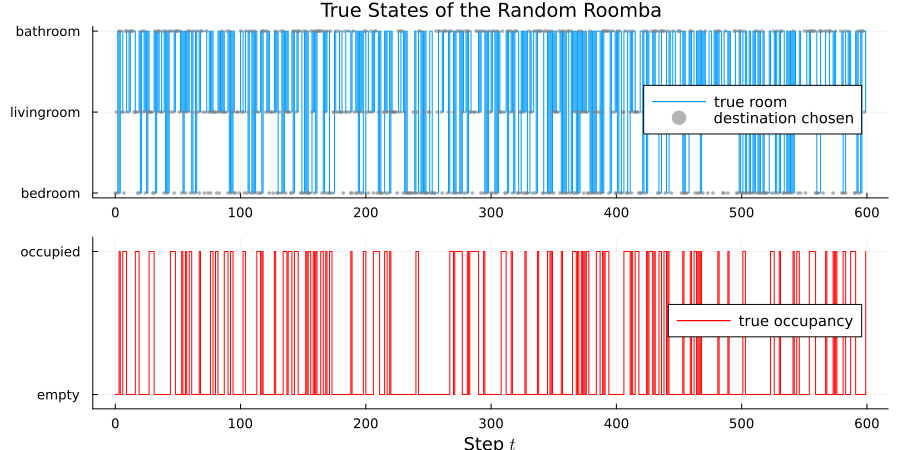

In [25]:
true_states   = [argmax(Lŝˣ[roomoccupancy_n]) for Lŝˣ in parent(Lŝˣː)]    ## joint state index (1..6) of ŝ^{*(t,0)}, t = 0, ..., T
rooms         = (true_states .+ 1) .÷ 2                      ## 1,2 → 1 (bedroom); 3,4 → 2 (livingroom); 5,6 → 3 (bathroom)
true_occupied = iseven.(true_states)                         ## states 2, 4, 6 are occupied
destinations  = [argmax(Lû[destination_n]) for Lû in parent(Lûː)]       ## chosen destination û^{(t,0)}, t = 0, ..., T-1

p_room = plot(0:T, rooms, linetype=:steppost, linestyle=:solid, leg=:right,
    label="true room", title="True States of the Random Roomba",
    yticks=(1:3, action_labels))
scatter!(p_room, 0:T-1, destinations, markersize=2, markerstrokewidth=0, color=:gray, alpha=0.6,
    label="destination chosen")
p_occ  = plot(0:T, true_occupied, linetype=:steppost, linestyle=:solid, leg=:right,
    label="true occupancy", xlabel="Step \$t\$",
    yticks=([0, 1], ["empty", "occupied"]), ylims=(-0.1, 1.1), color=:red)
plot(p_room, p_occ, layout=@layout([a; b]), size=(900, 450))

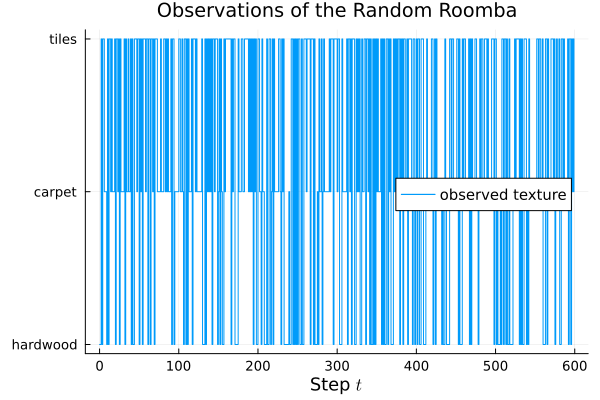

In [26]:
textures = [argmax(Lô[texture_m]) for Lô in parent(Lôː)]    ## texture index (1, 2, 3) of ô^{(t,0)} for t = 0, ..., T
plot(title="Observations of the Random Roomba")
plot!(
    0:T, textures, linetype=:steppost, linestyle=:solid, leg=:right,
    label="observed texture", xlabel="Step \$t\$", yticks=(1:3, texture_labels))

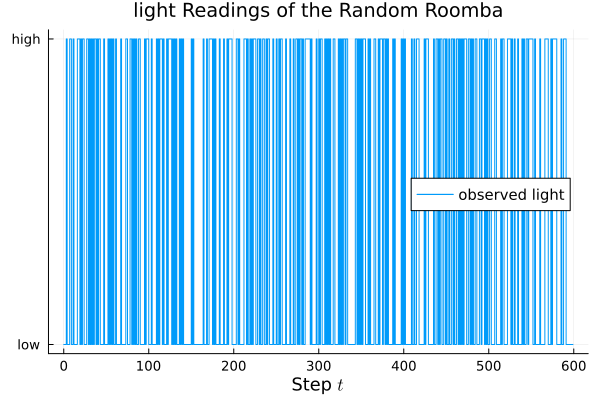

In [27]:
lights = [argmax(Lô[light_m]) for Lô in parent(Lôː)]    ## light index (1 = low, 2 = high) of ô^{(t,1)} for t = 0, ..., T
plot(title="light Readings of the Random Roomba")
plot!(
    0:T, lights, linetype=:steppost, linestyle=:solid, leg=:right,
    label="observed light", xlabel="Step \$t\$", yticks=(1:2, light_labels))

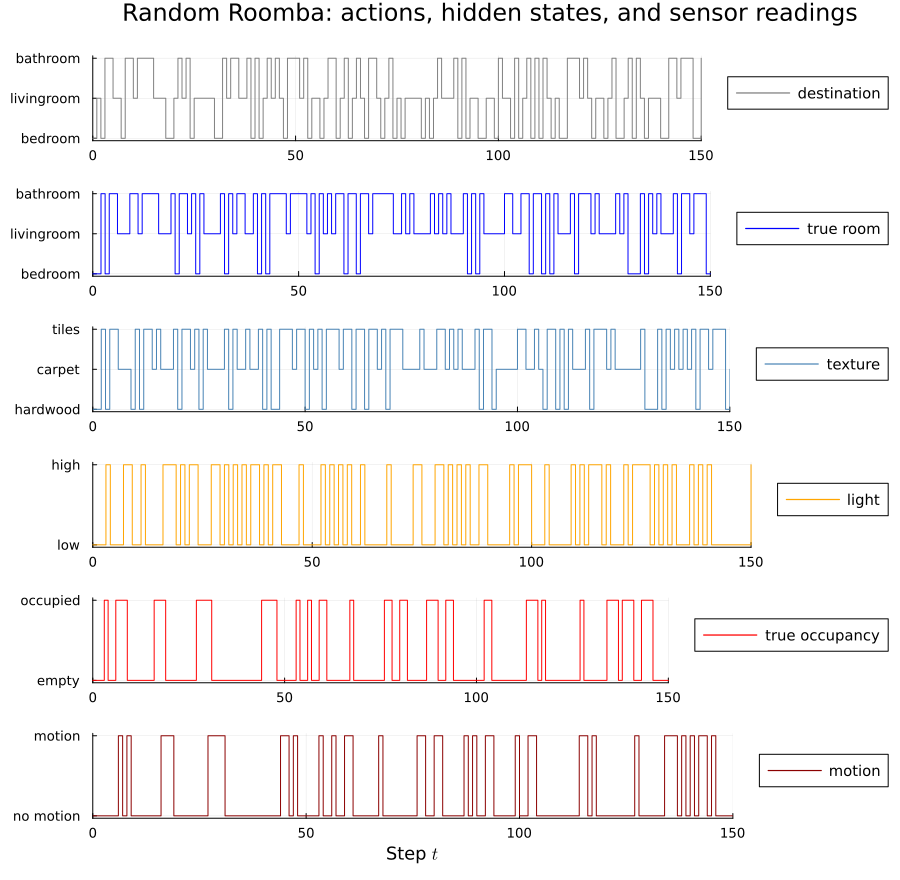

In [28]:
true_states  = [argmax(Lŝˣ[roomoccupancy_n]) for Lŝˣ in parent(Lŝˣː)]    ## joint state index 1..6
rooms        = (true_states .+ 1) .÷ 2                      ## 1 bedroom, 2 livingroom, 3 bathroom
occupancies  = iseven.(true_states) .+ 1                    ## 1 empty, 2 occupied
textures     = [argmax(Lô[texture_m]) for Lô in parent(Lôː)]        ## 1 hardwood, 2 carpet, 3 tiles
lights       = [argmax(Lô[light_m]) for Lô in parent(Lôː)]        ## 1 low, 2 high
motions      = [argmax(Lô[motion_m]) for Lô in parent(Lôː)]        ## 1 no motion, 2 motion
destinations = [argmax(Lû[destination_n]) for Lû in parent(Lûː)]        ## 1 bedroom, 2 livingroom, 3 bathroom (t = 0, ..., T-1)

window = (0, 150)    ## zoom in so individual ticks are visible; use (0, T) for the full run
panel(ts, y, ticks, label, color) = plot(ts, y, linetype=:steppost, label=label, color=color,
                                         yticks=ticks, xlims=window, legend=:outerright)

plot(
    panel(0:T-1, destinations, (1:3, action_labels), "destination",    :gray),
    panel(0:T,   rooms,        (1:3, action_labels), "true room",      :blue),
    panel(0:T,   textures,     (1:3, texture_labels),        "texture",        :steelblue),
    panel(0:T,   lights,       (1:2, light_labels),                        "light",          :orange),
    panel(0:T,   occupancies,  (1:2, ["empty", "occupied"]),                  "true occupancy", :red),
    panel(0:T,   motions,      (1:2, motion_labels),                "motion",         :darkred),
    layout=(6, 1), size=(900, 880), link=:x, xlabel=["" "" "" "" "" "Step \$t\$"],
    plot_title="Random Roomba: actions, hidden states, and sensor readings",
)

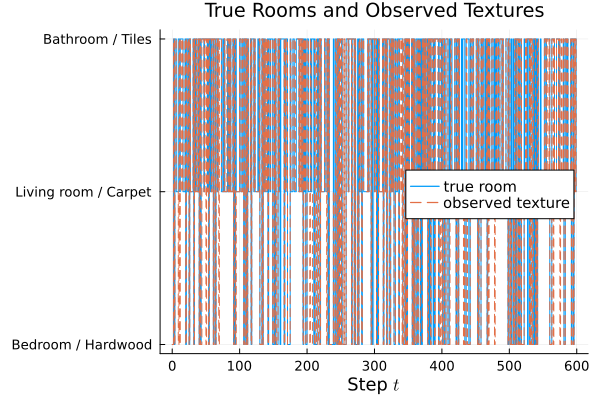

In [29]:
plot(title="True Rooms and Observed Textures")
plot!(0:T, rooms, linetype=:steppost, label="true room",
      yticks=(1:3, ["Bedroom / Hardwood", "Living room / Carpet", "Bathroom / Tiles"]))
plot!(0:T, textures, linetype=:steppost, linestyle=:dash, label="observed texture",
      xlabel="Step \$t\$", leg=:right)

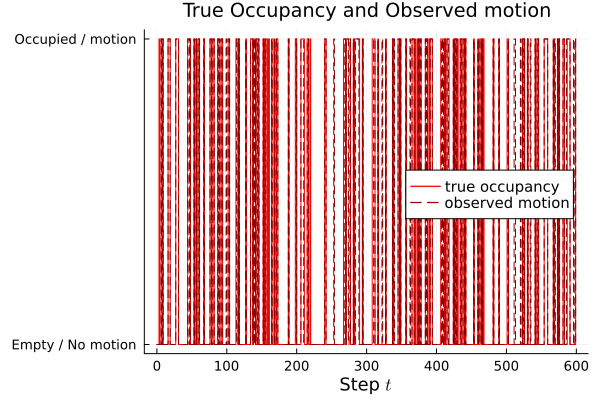

In [30]:
plot(title="True Occupancy and Observed motion")
plot!(0:T, occupancies, linetype=:steppost, label="true occupancy", color=:red,
      yticks=(1:2, ["Empty / No motion", "Occupied / motion"]))
plot!(0:T, motions, linetype=:steppost, linestyle=:dash, label="observed motion", color=:darkred,
      xlabel="Step \$t\$", leg=:right)

In [31]:
mistakes = count(rooms .!= textures)
println("camera mistakes: $mistakes of $(T+1) ticks ($(round(100*mistakes/(T+1), digits=1))%)")

camera mistakes: 77 of 600 ticks (12.8%)


In [32]:
occupied     = occupancies .== 2
misses       = count(occupied .& (motions .== 1))   ## person present, no motion detected
false_alarms = count(.!occupied .& (motions .== 2)) ## room empty, motion detected
println("motion sensor misses:       $misses of $(count(occupied)) occupied ticks ($(round(100*misses/count(occupied), digits=1))%)")
println("motion sensor false alarms: $false_alarms of $(count(.!occupied)) empty ticks ($(round(100*false_alarms/count(.!occupied), digits=1))%)")

motion sensor misses:       34 of 163 occupied ticks (20.9%)
motion sensor false alarms: 13 of 437 empty ticks (3.0%)


In [33]:
## The simulated fractions should come out close to 0.5, 0.85 and 0.1.
## As with the camera's mistakes, they won't be exact, because the data is a
## random sample. This uses rooms and lights from the previous plot cells,
## so run those first. A^{*(1)} has one column per joint state; room r's value
## is in column 2r-1 (empty), which equals column 2r (occupied).
for (r, room) in enumerate(action_labels)
    in_room   = rooms .== r
    frac_high = mean(lights[in_room] .== 2)
    println("$room: high light $(round(frac_high, digits=2)) of $(count(in_room)) ticks (A^{*(1)}: $(LAˣ[light_m][2, 2r-1]))")
end

bedroom: high light 0.55 of 142 ticks (A^{*(1)}: 0.5)
livingroom: high light 0.85 of 168 ticks (A^{*(1)}: 0.85)
bathroom: high light 0.07 of 290 ticks (A^{*(1)}: 0.1)


In [34]:
println("random Roomba, disturbance: $(round(100*mean(occupancies .== 2), digits=1))% of ticks in an occupied room")
println("random Roomba, coverage:    ",
        join(["$(r): $(round(100*mean(rooms .== i), digits=1))%" for (i, r) in enumerate(["bedroom", "livingroom", "bathroom"])], ", "))

random Roomba, disturbance: 27.2% of ticks in an occupied room
random Roomba, coverage:    bedroom: 23.7%, livingroom: 28.0%, bathroom: 48.3%


In [35]:
## ---------- random Roomba: reference values for disturbance and coverage (4.3.5) ----------
true_states_random = [argmax(Lŝˣ[roomoccupancy_n]) for Lŝˣ in parent(Lŝˣː)]    ## joint state index 1..6
rooms_random       = (true_states_random .+ 1) .÷ 2               ## 1 bedroom, 2 livingroom, 3 bathroom

disturbance_random = mean(iseven.(true_states_random))            ## J_disturb: fraction of ticks in an occupied room
coverage_random    = [mean(rooms_random .== r) for r in 1:3]      ## J_cover(r): fraction of ticks in each room

println("random Roomba, disturbance: $(round(100*disturbance_random, digits=1))% of ticks in an occupied room")
println("random Roomba, coverage (bedroom, livingroom, bathroom): ", round.(100 .* coverage_random, digits=1), "%")

random Roomba, disturbance: 27.2% of ticks in an occupied room
random Roomba, coverage (bedroom, livingroom, bathroom): [23.7, 28.0, 48.3]%


### 4.4 Uncertainty Model

The uncertainty in the environment is captured in the state transition array $\boldsymbol{B}^{\ast(0)}$ (factor 0, *room occupancy*), with one transition matrix per action, and the observation generation matrices $\boldsymbol{A}^{\ast(0)}$ (modality 0, Texture), $\boldsymbol{A}^{\ast(1)}$ (modality 1, Light) and $\boldsymbol{A}^{\ast(2)}$ (modality 2, Motion). Their entries are the probabilities of the Roomba's moves, including moves that fail, and of changes in occupancy, and of the readings of the camera, the light sensor and the motion sensor. The actions themselves add no uncertainty: the agent knows which action it chose, only not exactly what will come of it. The initial state adds no uncertainty either, because the Roomba always starts in the empty bedroom.

On the agent's side, there is no uncertainty about how the environment works: in this part, the agent is given $\mathbf{A} = \mathbf{A}^{\ast}$ and $\mathbf{B} = \mathbf{B}^{\ast}$. What remains is uncertainty about the state: which room the Roomba is in, whether that room is occupied, and, when planning, where its actions will lead and whom it will meet there. The agent handles this uncertainty with its beliefs, and takes it into account when choosing actions.

### 4.5 Agent / Generative Model
#### 4.5.1 State and Observation variables
On the agent's side, the state of the environment at time $t$ is not known: the agent represents it by a (compound) tuple of categorical random variables, one per state factor (here a single factor):

$$
\mathbf{s}^{(t)} = \big(s^{(t,0)}\big)
$$

where the state factors are:

- factor 0 (*room occupancy*):
    - $s^{(t,0)} \in \{\text{bedroom-empty}, \text{bedroom-occupied}, \text{livingroom-empty}, \text{livingroom-occupied}, \text{bathroom-empty}, \text{bathroom-occupied}\}$

The agent never observes $s^{(t,0)}$ directly. What it holds instead is a belief, the probability vector $\boldsymbol{s}^{(t,0)} \in [0,1]^{6}$, with one probability per combination of room and occupancy. From it, the agent's belief about the room follows by adding up the empty and occupied entries of each room, and its belief that the current room is occupied by adding up the three occupied entries.

The initial state prior is given by

$$
P_D\big(s^{(0,0)}\big) = \mathcal{Cat}\big(s^{(0,0)};\, \boldsymbol{D}^{(0)}\big)
$$

where $\boldsymbol{D}^{(0)} \in [0,1]^{6}$ parameterizes the categorical distribution of $s^{(0,0)}$. Unlike the environment, the agent does not know that the Roomba starts in the empty bedroom, so it uses the uniform prior $\boldsymbol{D}^{(0)} = [\tfrac{1}{6}, \tfrac{1}{6}, \tfrac{1}{6}, \tfrac{1}{6}, \tfrac{1}{6}, \tfrac{1}{6}]^{\top}$.

The (compound) observation tuple received by the agent at time $t$ is the same one the environment generates:

$$
\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{(t,0)}, \hat{\boldsymbol{o}}^{(t,1)}, \hat{\boldsymbol{o}}^{(t,2)}\big)
$$

where the observation modalities are:

- modality 0 (*texture*):
    - $o^{(t,0)} \in \{\text{hardwood}, \text{carpet}, \text{tiles}\}$,
    - one-hot encoded as $\hat{\boldsymbol{o}}^{(t,0)} \in \big\{[1,0,0]^{\top}, [0,1,0]^{\top}, [0,0,1]^{\top}\big\}$
- modality 1 (*light*):
    - $o^{(t,1)} \in \{\text{low}, \text{high}\}$,
    - one-hot encoded as $\hat{\boldsymbol{o}}^{(t,1)} \in \big\{[1,0]^{\top}, [0,1]^{\top}\big\}$
- modality 2 (*motion*):
    - $o^{(t,2)} \in \{\text{no motion}, \text{motion}\}$,
    - one-hot encoded as $\hat{\boldsymbol{o}}^{(t,2)} \in \big\{[1,0]^{\top}, [0,1]^{\top}\big\}$

New in this part, the agent also chooses actions, and it prefers some observations over others. Both are described in 4.5.2.

#### 4.5.2 Decision variables

New in this part, the agent makes decisions. At each time step, it chooses an action: the room the Roomba heads for. The agent represents its action at time $t$ by a (compound) tuple of categorical random variables, one per control factor (here a single factor):

$$
\mathbf{u}^{(t)} = \big(u^{(t,0)}\big)
$$

where the control factors are:

- control factor 0 (*destination*), acting on state factor 0 (*room occupancy*):
    - $u^{(t,0)} \in \{\text{bedroom}, \text{livingroom}, \text{bathroom}\}$

Heading for the room the Roomba is already in means staying put. Unlike the state, the agent always knows which action it has taken: once chosen, the action is a realized value $\hat{\boldsymbol{u}}^{(t,0)}$, which the agent hands to the environment and also uses itself, to predict how the state will change. What the agent does not know is the outcome: whether the move succeeds, and whether the room it reaches is occupied.

**Policies.** To choose an action, the agent looks $H$ steps ahead. It considers candidate policies, i.e. sequences of $H$ actions, collected as the rows of a matrix $\boldsymbol{V}$: row $p$ is the slice $\boldsymbol{V}^{[p]}$, and $V^{[p,\tau,0]}$ is the *destination* it prescribes at step $\tau = 0, \ldots, H-1$. With three possible actions per step, there are $3^H$ policies; for example, $H = 2$ gives 9 policies, such as "bathroom", then "bathroom" again. The agent scores each policy by its expected free energy (see 4.5.6), turns the scores into a probability for each policy, and from those derives a probability for each possible next action. Only the first action of the chosen policy is carried out; at the next time step, the agent observes the result and plans again.

#### 4.5.3 Preference variables / Setpoints

The agent's goal is a preference over observations: it prefers to receive the observations it wants to be true. There is one log-preference vector per modality, $\log\boldsymbol{C}^{(m)}$, collected in the tuple $\mathbf{C}$. $\log\boldsymbol{C}$ is given directly, not as the logarithm of a normalized distribution. Normalizing a preference and then taking the logarithm would add the same constant to every policy's $G_{\Sigma}^{[p]}$ and would change no decision.

- $\log\boldsymbol{C}^{(0)}$ (*texture*) and $\log\boldsymbol{C}^{(1)}$ (*light*) are $\boldsymbol{0}$. Those modalities are used for perception only, and the text of the score says so by adding nothing to the risk.
- $\log\boldsymbol{C}^{(2)}$ (*motion*) is $\log(0.9, 0.1)$, a preference for "no motion". Observing "motion" is then $\log(0.9/0.1) \approx 2.2$ worse than observing "no motion".

The agent cannot prefer an unoccupied room directly, because it never observes occupancy. It prefers the observation that indicates an unoccupied room, and it chooses actions it expects to produce that observation. Preferences are stated over what the agent can sense, not over the hidden state.

How strongly the agent prefers "no motion" is the gap inside $\log\boldsymbol{C}^{(2)}$. A wider gap makes the choices more driven by avoiding "motion", and less by reducing uncertainty about *room occupancy*.

The modalities *texture* and *light* still locate the Roomba, which the agent needs in order to predict where an action leads. They do not make one room more attractive than another.

#### 4.5.4 State Transition and Observation Generation functions
The state transition function is given by

$$
P_B\big(s^{(t,0)} \mid s^{(t-1,0)}, u^{(t-1,0)}\big) = \mathcal{Cat}\big(s^{(t,0)};\, \boldsymbol{B}^{(0)}[\bullet, s^{(t-1,0)}, u^{(t-1,0)}]\big)
$$

where $\boldsymbol{B}^{(0)}[\bullet, s^{(t-1,0)}, u^{(t-1,0)}]$, the column of $\boldsymbol{B}^{(0)}$ for the previous room and occupancy, in the transition matrix of the action chosen at $t-1$, parameterizes the categorical distribution of $s^{(t,0)}$.

The observation generation functions, one per sensor, are given by

$$
P_A\big(o^{(t,m)} \mid s^{(t,0)}\big) = \mathcal{Cat}\big(o^{(t,m)};\, \boldsymbol{A}^{(m)}[\bullet, s^{(t,0)}]\big), \qquad m = 0, 1, 2
$$

where $\boldsymbol{A}^{(m)}[\bullet, s^{(t,0)}]$, the column of $\boldsymbol{A}^{(m)}$ for the current room and occupancy, parameterizes the categorical distribution of $o^{(t,m)}$: over textures for $m = 0$, over light intensities for $m = 1$, and over motion readings for $m = 2$. Observations do not depend on the action.

In this part, the agent is given its matrices: $\boldsymbol{A}^{(m)} = \boldsymbol{A}^{\ast(m)}$ and $\boldsymbol{B}^{(0)} = \boldsymbol{B}^{\ast(0)}$. They are known parameters, not random variables, so they appear as subscripts.

An entry of $\boldsymbol{A}^{(m)}$ is the probability of a specific observation given a specific state, and each column of $\boldsymbol{A}^{(m)}$ is a categorical distribution over observations. The same holds for each transition matrix $\boldsymbol{B}^{(0)}[\bullet, \bullet, u]$, with the next state in place of the observation. If the state were known, its column could be selected by multiplying with the one-hot encoding of that state. The agent, however, does not know the state; it only has its belief $\boldsymbol{s}^{(t,0)}$. Multiplying with the belief gives a weighted average of the columns.

**Inference.** After carrying out action $\hat{u}^{(t-1,0)}$, the agent predicts the new state as $\boldsymbol{B}^{(0)}[\bullet, \bullet, \hat{u}^{(t-1,0)}]\,\boldsymbol{s}^{(t-1,0)}$, and then updates this prediction with the observations it receives. Given the state, the three sensors are independent of each other, so the agent combines them by multiplying their likelihoods,

$$
P\big(o^{(t,0)}, o^{(t,1)}, o^{(t,2)} \mid s^{(t,0)}\big) = \prod_{m=0}^{2} P_A\big(o^{(t,m)} \mid s^{(t,0)}\big)
$$

so a state that explains all readings well gains belief, while a state that explains only some of them loses some. Texture and light mainly tell the rooms apart, since they depend only on the room, while motion tells empty from occupied, since it depends only on occupancy.

**Planning.** To evaluate policy $p$, the agent applies the same functions to the future, step by step, starting from its current belief:

$$
\boldsymbol{s}^{(0,0)}_{\pi^{[p]}} = \boldsymbol{B}^{(0)}\big[\bullet, \bullet, V^{[p,0,0]}\big]\,\boldsymbol{s}^{(t,0)},
\qquad
\boldsymbol{s}^{(\tau,0)}_{\pi^{[p]}} = \boldsymbol{B}^{(0)}\big[\bullet, \bullet, V^{[p,\tau,0]}\big]\,\boldsymbol{s}^{(\tau-1,0)}_{\pi^{[p]}} \quad (\tau > 0)
$$

$$
\boldsymbol{o}^{(\tau,m)}_{\pi^{[p]}} = \boldsymbol{A}^{(m)}\,\boldsymbol{s}^{(\tau,0)}_{\pi^{[p]}}
$$

Here $\boldsymbol{s}^{(\tau,0)}_{\pi^{[p]}}$ is the predicted belief about time $t + \tau + 1$ if the agent follows policy $p$, and $\boldsymbol{o}^{(\tau,m)}_{\pi^{[p]}}$ is the observation of sensor $m$ it then expects. No real observations are available for the future, so these predictions are never updated; they are what the agent compares with its preferences when it scores policy $p$ (see 4.5.6). For the motion sensor, for example, $\boldsymbol{o}^{(\tau,2)}_{\pi^{[p]}}$ tells the agent how likely it is to observe motion if it follows policy $p$, which is exactly what its preference for "no motion" is about.

#### 4.5.5 Implementation of the Agent / Generative Model / Internal Model
We start by specifying a probabilistic model for the agent that describes the agent's internal beliefs about the external dynamics of the environment. With control, this model has two parts. Up to the current time $t$, it describes what has happened: the states the Roomba went through, the observations it received, and the actions $\hat{u}^{(0:t-1,0)}$ the agent actually took. Beyond $t$, it describes what could happen over the next $H$ steps, depending on which policy $\pi^{(t)}$ the agent chooses. The generative model at time $t$ is defined as follows:

$$
\begin{aligned}
&P\big(o^{(0:t+H,0)}, o^{(0:t+H,1)}, o^{(0:t+H,2)}, s^{(0:t+H,0)}, \pi^{(t)} \mid \hat{u}^{(0:t-1,0)}\big) \\[4pt]
&\quad= \underbrace{P\big(\pi^{(t)}\big)}_{\substack{\text{policy}\\ \text{prior}}}
   \,\underbrace{P_D\big(s^{(0,0)}\big)}_{\substack{\text{state}\\ \text{prior}}}
   \prod_{t'=0}^{t+H} \prod_{m=0}^{2} \underbrace{P_A\big(o^{(t',m)} \mid s^{(t',0)}\big)}_{\substack{\text{observation-generation}\\ \text{model}}} \\[4pt]
&\qquad\times \underbrace{\prod_{t'=1}^{t} P_B\big(s^{(t',0)} \mid s^{(t'-1,0)}, \hat{u}^{(t'-1,0)}\big)}_{\text{past: actions taken}}
   \;\underbrace{\prod_{\tau=0}^{H-1} P_B\big(s^{(t+\tau+1,0)} \mid s^{(t+\tau,0)}, V^{[p,\tau,0]}\big)}_{\text{future: actions under policy } \pi^{(t)}}
\end{aligned}
$$

where $\boldsymbol{D}^{(0)}$ is the agent's uniform initial state prior from 4.5.1, and $\mathbf{A} = \mathbf{A}^{\ast}$ and $\mathbf{B} = \mathbf{B}^{\ast}$ are the matrices the agent is given. All of them are known parameters, so they appear as subscripts. Unlike in Part 3, there are no parameter priors: the agent learns nothing about its matrices in this part.

The two transition products differ only in where the action comes from. In the past, the action is the one the agent actually took, $\hat{u}^{(t'-1,0)}$, a known value. In the future, it is the action $V^{[p,\tau,0]}$ that the policy prescribes at step $\tau$; since the policy is not yet chosen, that action is $V^{[p,\tau,0]}$ when $\pi^{(t)} = p$. Step $\tau$ predicts time $t + \tau + 1$, as in 4.5.4.

The **policy prior** $P\big(\pi^{(t)}\big)$ is where the agent's preferences enter the model. In active inference, it is not chosen freely: policies are a priori more probable the lower their expected free energy,

$$
P\big(\pi^{(t)} = p\big) = \sigma(-\boldsymbol{G}_{\Sigma})^{[p]}
$$

where $\boldsymbol{G}_{\Sigma}$ collects the expected free energies $G_{\Sigma}^{[p]}$ of the policies, which depend on the preferences $\mathbf{C}$ from 4.5.3 (see 4.5.6), and $\sigma$ is the softmax. The agent thus expects to act in ways that lead to its preferred observations.

As before, the product over $m$ is where the three sensors are combined: at each time step, all three observations depend on the same state $s^{(t',0)}$, and given that state, they are independent. For the future, these observations are not yet available: the agent uses their expected values, $\boldsymbol{o}^{(\tau,m)}_{\pi^{[p]}}$ from 4.5.4, to evaluate each policy.

Now it is time to build our agent. Unlike in the previous parts, the agent does not learn anything: it is given its model of the world, i.e. the observation matrices $\mathbf{A} = \mathbf{A}^{\ast}$, the transition matrices $\mathbf{B} = \mathbf{B}^{\ast}$ (one per action), the uniform initial prior $\boldsymbol{D}^{(0)}$, and its preferences $\mathbf{C}$ from 4.5.3. What it has to do is use this model, at every tick, in three steps.

**1. Update its belief (perception).** After the environment has carried out the previous action $\hat{u}^{(t-1,0)}$ and returned the new observations $\hat{\mathbf{o}}^{(t)}$, the agent first predicts where the Roomba is likely to be now, then corrects that prediction with what its sensors report:

$$
\boldsymbol{s}^{(t,0)} \;\propto\; \Big(\prod_{m=0}^{2} \boldsymbol{A}^{(m)\top} \hat{\boldsymbol{o}}^{(t,m)}\Big) \odot \Big(\boldsymbol{B}^{(0)}[\bullet, \bullet, \hat{u}^{(t-1,0)}]\,\boldsymbol{s}^{(t-1,0)}\Big)
$$

where $\boldsymbol{A}^{(m)\top} \hat{\boldsymbol{o}}^{(t,m)}$ picks out the row of $\boldsymbol{A}^{(m)}$ for the received observation, i.e. the likelihood of that observation under each of the six states, the products are taken entry by entry ($\odot$), and the result is normalized to sum to 1. At $t = 0$, the prediction is replaced by the initial prior $\boldsymbol{D}^{(0)}$. With known matrices and a single state factor, this is exact Bayesian filtering: no variational approximation is needed.

**2. Evaluate the policies (planning).** For each policy $p$, the agent predicts its beliefs and observations over the next $H$ steps, as in 4.5.4, and scores the policy by its expected free energy $G_{\Sigma}^{[p]}$ (see 4.5.6). The score favors policies that are expected to lead to preferred observations, i.e. "no motion", and policies that are expected to reduce the agent's uncertainty about the state.

**3. Choose an action (decision).** The scores are turned into a posterior over policies, $Q\big(\pi^{(t)} = p\big) = \sigma(-\boldsymbol{G}_{\Sigma})^{[p]}$, and from it into a distribution over the next action, $Q\big(u^{(t,0)}\big)$, by adding up the probabilities of all policies that start with that action. The agent then carries out the most probable action, $\hat{u}^{(t,0)}$, and the cycle repeats at the next tick.

Since the model is small, with six states, three actions and a short planning horizon, all three steps can be computed directly in Julia, without `RxInfer`: step 1 is a few matrix products, and step 2 evaluates all $3^H$ policies explicitly, e.g. 9 policies for $H = 2$. This keeps every quantity of Algorithm 18 visible in the code. `RxInfer` also supports active inference, as planning formulated as inference, which becomes attractive for larger models; this is a possible direction for a later part. Let's build the agent!

In [36]:
## ---------- the agent's model: given, not learned ----------
LA = LAˣ                                               ## A^{(m)} = A^{*(m)}, m = 0, 1, 2
LB = LBˣ                                               ## B^{(0)} = B^{*(0)}, 6×6×3 (one matrix per action)
_Bı0ı = LB[roomoccupancy_n]                            ## B^{(0)}
LD = tuple0(fill(1/6, 6))                              ## D^{(0)}: uniform initial prior over the 6 joint states
_Dı0ı = LD[roomoccupancy_n]                            ## D^{(0)}
LC = tuple0(zeros(3),          ## log C^{(0)} = 0: texture, perception only
            zeros(2),          ## log C^{(1)} = 0: light, perception only
            log.([0.9, 0.1]))  ## log C^{(2)}: motion, preference for "no motion"

## ---------- policies: all action sequences of length H ----------
H  = 2                                                 ## planning horizon
_V = [p[τ] for p in vec(collect(Iterators.product(ntuple(_ -> 1:3, H)...))), τ in 1:H]   ## P×H; column τ+1 is step τ
P  = size(_V, 1)                                       ## number of policies, 3^H

## ---------- helpers ----------
normalize(v)  = v ./ sum(v)
log_stable(x) = log.(max.(x, 1e-16))                   ## avoids log(0)
softmax(x)    = normalize(exp.(x .- maximum(x)))
LH = tuple0((-vec(sum(LA[m] .* log_stable(LA[m]), dims=1)) for m in eachindex(LA))...)   ## H^{(m)}: entropy of each column

## ---------- step 1: perception (exact Bayesian filtering) ----------
## s^{(t,0)} ∝ (∏_m A^{[m]ᵀ} ô^{(t,m)}) ⊙ (B^{(0)}[•,•,û^{(t-1,0)}] s^{(t-1,0)}); at t = 0 the prediction is D^{(0)}
function perceive(Lsₜ₋₁, Lôₜ, ûₜ₋₁)
    prediction = Lsₜ₋₁ === nothing ? LD[roomoccupancy_n] : LB[roomoccupancy_n][:, :, ûₜ₋₁] * Lsₜ₋₁[roomoccupancy_n]
    likelihood = reduce((a, b) -> a .* b, (LA[m]' * Lôₜ[m] for m in eachindex(LA)))    ## ∏_m A^{[m]ᵀ} ô^{(t,m)}, entry by entry (⊙)
    tuple0(normalize(likelihood .* prediction))      ## Lsₜ = s^{(t)}
end

## ---------- step 2: expected free energy of policy p ----------
## G_{\Sigma}^{[p]} = Σ_τ Σ_m [ o^{(τ,m)}_{π^{[p]}}·(log o^{(τ,m)}_{π^{[p]}} - log C^{(m)})  +  H^{(m)}·s^{(τ,0)}_{π^{[p]}} ]
##                      (risk: expected vs. preferred observations)    (ambiguity: expected sensor noise)
function efe(Lsₜ, p)
    s = Lsₜ[roomoccupancy_n]
    G = 0.0
    for τ in 1:H                                       ## code τ = math τ + 1
        s = LB[roomoccupancy_n][:, :, _V[p, τ]] * s                  ## s^{(τ,0)}_{π^{[p]}}: predicted belief
        for m in eachindex(LA)
            o  = LA[m] * s                             ## o^{(τ,m)}_{π^{[p]}}: expected observation
            G += o' * (log_stable(o) - LC[m]) + LH[m]' * s
        end
    end
    G
end

## ---------- step 3: from policy scores to an action ----------
function plan(Lsₜ)
    _G_Σ  = [efe(Lsₜ, p) for p in 1:P]                  ## G_{\Sigma}^{[p]}, one per policy
    _π = softmax(-_G_Σ)                                 ## π = σ(-G_Σ), and π^{[p]} = Q(π^{(t)} = p)
    _qu = [sum(_π[_V[:, 1] .== u]) for u in 1:3]      ## Q(u^{(t,0)}): add up policies by their first action
    (_G_Σ, _π, _qu)
end

choose(_qu) = argmax(_qu)                              ## û^{(t,0)}: the most probable action (1 bedroom, 2 livingroom, 3 bathroom)

choose (generic function with 1 method)

**Notes on the agent code.**

**Names.** The code mirrors the agent's math.

- `LA`, `LB`, `LC` and `LD` are tuples, upright bold $\mathbf{A}$, $\mathbf{B}$, $\mathbf{C}$ and $\mathbf{D}$, built with `tuple0`. `LA[m]` is $\boldsymbol{A}^{(m)}$. `_Bı0ı` is $\boldsymbol{B}^{(0)}$, the same array as `LB[roomoccupancy_n]`. `LC[m]` holds $\log\boldsymbol{C}^{(m)}$, not a probability vector. `LA` and `LB` are the environment's `LAˣ` and `LBˣ`: the agent is given its model.
- `_V` is the decision matrix $\boldsymbol{V}$. `_G_Σ` is $\boldsymbol{G}_{\Sigma}$. `_π` is the policy posterior $\boldsymbol{\pi} = \sigma(-\boldsymbol{G}_{\Sigma})$. `_qu` is $Q(u^{(t,0)})$.
- `Lsₜ` and `Lsₜ₋₁` are the belief tuples $\mathbf{s}^{(t)}$ and $\mathbf{s}^{(t-1)}$. `Lsₜ[roomoccupancy_n]` is the belief $\boldsymbol{s}^{(t,0)}$.
- `LH[m]` is $\boldsymbol{H}^{(m)}$, the entropy of each column of $\boldsymbol{A}^{(m)}$. It is computed once, because the matrices do not change.

**Structure.** One function per step.

- `perceive` is the belief update. It predicts with the transition slice of the previous *destination*, multiplies by the likelihoods of the three observations, and normalizes. At $t = 0$ the prediction is $\boldsymbol{D}^{(0)}$. This is exact Bayesian filtering.
- `efe` scores one policy. It rolls the belief forward through that policy's actions and sums risk and ambiguity over the steps and the three modalities. Risk uses $\log\boldsymbol{C}^{(m)}$ directly.
- `plan` turns the scores into $\boldsymbol{\pi}$ and into $Q(u^{(t,0)})$. `choose` picks the most probable *destination*.

**Indexing.** Tuples are 0-based. Inside an array, Julia stays 1-based: the six values, the three destinations, and the planning steps. The math's step $\tau = 0, \ldots, H-1$ is column $\tau + 1$ of `_V`.

This part does not use `RxInfer`. With known matrices and one state factor, the three steps are a few lines of Julia.

Next, we define the agent and the time-stepping procedure.

In [37]:
function create_agent()
    Lsₜ₋₁ = nothing    ## s^{(t-1)}: the previous belief (none before t = 0)
    ûₜ₋₁  = nothing    ## û^{(t-1,0)}: the previous action, as an index 1..3 (none before t = 0)
    Lsₜ   = nothing    ## s^{(t)}: the current belief
    ûₜ    = nothing    ## û^{(t,0)}: the current action
    _G_Σ = _π = _qu = nothing    ## the current plan: G, Q(π^{(t)}), Q(u^{(t,0)})

    ## step 1 and 2: update the belief with the new observations, then score all policies
    compute = (Lôₜ) -> begin
        Lsₜ = perceive(Lsₜ₋₁, Lôₜ, ûₜ₋₁)
        _G_Σ, _π, _qu = plan(Lsₜ)
        nothing
    end

    ## step 3: choose the next action, returned as a one-hot action tuple û^{(t)}
    act = () -> begin
        ûₜ = choose(_qu)
        tuple0(Float64.(1:3 .== ûₜ))
    end

    ## predicted beliefs s^{(τ,0)}_{π^{[p]}}, τ = 0, ..., H-1, under policy p (for inspection)
    future = (p) -> begin
        s = Lsₜ[roomoccupancy_n]
        Lsπː = Any[]
        for τ in 1:H
            s = LB[roomoccupancy_n][:, :, _V[p, τ]] * s
            push!(Lsπː, tuple0(s))
        end
        offset0(Lsπː)
    end

    ## move one tick forward: the current belief and action become the previous ones
    slide = () -> begin
        Lsₜ₋₁ = Lsₜ
        ûₜ₋₁  = ûₜ
        nothing
    end

    belief = () -> Lsₜ                  ## s^{(t)}, for recording
    scores = () -> (_G_Σ, _π, _qu)       ## the current plan, for inspection

    return (compute, act, future, slide, belief, scores)
end

create_agent (generic function with 1 method)

#### 4.5.6 Expected free energy and action selection

The per-step expected free energy of policy $p$ at imagined step $\tau$ is risk plus ambiguity. Risk is the gap between the expected observation and the log-preference. Ambiguity is the expected entropy of the sensors:

$$
G^{[p,\tau]} = \sum_{m=0}^{2} \Big( \boldsymbol{o}^{(\tau,m)}_{\pi^{[p]}} \cdot \big(\log \boldsymbol{o}^{(\tau,m)}_{\pi^{[p]}} - \log\boldsymbol{C}^{(m)}\big) + \boldsymbol{H}^{(m)} \cdot \boldsymbol{s}^{(\tau,0)}_{\pi^{[p]}} \Big)
$$

with $\tau = 0, \ldots, H - 1$. The sum over the steps is one number per policy,

$$
G_{\Sigma}^{[p]} = \sum_{\tau=0}^{H-1} G^{[p,\tau]}, \qquad \boldsymbol{G}_{\Sigma} \in \mathbb{R}^{P}.
$$

There is no habit prior and no cost of effort, so the policy posterior is

$$
\boldsymbol{\pi} = \sigma(-\boldsymbol{G}_{\Sigma}), \qquad \pi^{[p]} = Q(\pi^{(t)} = p).
$$

The posterior over the next *destination* adds up the policies whose first action is that *destination*,

$$
Q(u^{(t,0)}) = \sum_{p} \delta_{u = V^{[p,0,0]}} \, Q(\pi^{(t)} = p).
$$

The agent carries out the most probable value, $\hat{u}^{(t,0)} = \arg\max_{u} Q(u^{(t,0)})$. Only that first action is executed. At the next tick the agent observes the result and plans again, so the later steps of the policy are a forecast, not a commitment.

$\log\boldsymbol{C}^{(0)}$ and $\log\boldsymbol{C}^{(1)}$ are $\boldsymbol{0}$, so *texture* and *light* contribute only through ambiguity and through the belief that carries into later steps. The risk that actually steers the Roomba is the *motion* term.

### 4.6 Agent Evaluation

The agent and the environment now run together for $T + 1 = 600$ ticks. At each tick the environment reports $\hat{\mathbf{o}}^{(t)}$, the agent updates $\boldsymbol{s}^{(t,0)}$ and chooses $\hat{\boldsymbol{u}}^{(t)}$, the environment carries the action out, and the agent slides one tick forward. The order is the series protocol: execute from $t = 1$, then state, observe, compute, act while $t < T$, slide.

A controller that ignores the model is not given a separate section. The baselines are the four strategies of 4.2: three fixed destinations, and a random *destination*.

The detail run uses the same environment seed as the random Roomba in 4.3.6, seed 42, so the comparison with that one random trajectory is only about how the actions are chosen. That single trajectory is for reading the beliefs. The comparison that the conclusion uses is the average over 30 seeds, later in this section.

During the run we record $\hat{\mathbf{s}}^{\ast(0:T)}$, $\hat{\mathbf{o}}^{(0:T)}$, $\hat{\mathbf{u}}^{(0:T-1)}$ and $\boldsymbol{s}^{(0:T,0)}$, and from them the measures of 4.3.5. The belief is exact Bayesian filtering, so there is no free-energy curve over iterations.

In [38]:
## ---------- simulation parameters ----------
## Time steps t = 0, ..., T (600 ticks)
T = 599

## Initial state: the Roomba starts in the empty bedroom
## positions: 1 bedroom-empty, 2 bedroom-occupied, 3 livingroom-empty,
##            4 livingroom-occupied, 5 bathroom-empty, 6 bathroom-occupied
Lŝˣ₀ = tuple0([1.0, 0.0, 0.0, 0.0, 0.0, 0.0])    ## ŝ^{*(0)} = (ŝ^{*(0,0)})

1-element OffsetArray(::Vector{Vector{Float64}}, 0:0) with eltype Vector{Float64} with indices 0:0:
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]

In [ ]:
## OVERRIDES

Let's take a look at our results. If the agent's preferences work, the Roomba should spend clearly less of its time in occupied rooms than the random Roomba from 4.3 (a lower **disturbance**), while still visiting all three rooms (a reasonable **coverage**). Behind this behavior, the agent should keep good track of where the Roomba is and whether its room is occupied (high **tracking** accuracies), since it can only avoid company it knows about.

It is also worth looking at how the agent behaves, not just how well. We expect it to leave a room soon after detecting motion there, to linger in rooms that stay quiet, and to prefer rooms that are rarely occupied, such as the bathroom, while still checking the others from time to time, since occupancy changes and a room that was busy may have become quiet. Let's see if it worked.

In [39]:
## Environment and agent
(execute_ai, observe_ai, state_ai) = create_envir(; LAˣ=LAˣ, LBˣ=LBˣ, Lŝˣ₀=Lŝˣ₀)
(compute_ai, act_ai, future_ai, slide_ai, belief_ai, scores_ai) = create_agent()

Lŝˣː = offset0(Vector{Any}(undef, T+1))    ## ŝ^{*(0:T)}: true states (room and occupancy)
Lôː  = offset0(Vector{Any}(undef, T+1))    ## ô^{(0:T)}: observations, each a tuple (texture, light, motion)
Lûː  = offset0(Vector{Any}(undef, T))      ## û^{(0:T-1)}: chosen actions, each a tuple (destination)
Lsː  = offset0(Vector{Any}(undef, T+1))    ## s^{(0:T)}: the agent's beliefs, each a tuple (room occupancy)
Lquː = offset0(Vector{Any}(undef, T+1))    ## Q(u^{(t,0)}): the agent's action probabilities at each tick

for t = 0:T
    t > 0 && execute_ai(Lûː[t-1])         ## 4. the environment carries out the previous action
    Lŝˣː[t] = state_ai()
    Lôː[t]  = observe_ai()                ## 1. the environment reports the observations
    compute_ai(Lôː[t])                    ## 2.–3. the agent updates its belief and scores the policies
    Lsː[t]  = belief_ai()
    Lquː[t] = scores_ai()[3]
    if t < T
        Lûː[t] = act_ai()                 ## 3. the agent chooses the next destination
        slide_ai()                        ## 5. the agent moves one tick forward
    end
end

In [40]:
[Lŝˣ[roomoccupancy_n] for Lŝˣ in Lŝˣː] ## ŝ^{*(t,0)} for t = 0, ..., T: the true room occupancy factor (one-hot over 6 joint states)

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 1.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 ⋮
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]

In [41]:
[action_labels[argmax(Lû[destination_n])] for Lû in Lûː]    ## destination chosen by the agent at t = 0, ..., T-1, by name

599-element OffsetArray(::Vector{String}, 0:598) with eltype String with indices 0:598:
 "livingroom"
 "bedroom"
 "livingroom"
 "bedroom"
 "livingroom"
 "bedroom"
 "livingroom"
 "bedroom"
 "livingroom"
 "livingroom"
 ⋮
 "bedroom"
 "livingroom"
 "bedroom"
 "livingroom"
 "bedroom"
 "livingroom"
 "bedroom"
 "livingroom"
 "bedroom"

In [42]:
[round.(Ls[roomoccupancy_n], digits=2) for Ls in Lsː]    ## s^{(t,0)} for t = 0, ..., T: the agent's belief over the 6 joint states

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [0.74, 0.16, 0.01, 0.0, 0.07, 0.02]
 [0.04, 0.0, 0.16, 0.03, 0.75, 0.02]
 [0.89, 0.08, 0.0, 0.0, 0.04, 0.0]
 [0.0, 0.0, 0.0, 0.0, 0.97, 0.02]
 [0.92, 0.08, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 0.97, 0.02]
 [0.13, 0.87, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 0.98, 0.02]
 [0.92, 0.08, 0.0, 0.0, 0.0, 0.0]
 [0.51, 0.01, 0.0, 0.0, 0.47, 0.01]
 ⋮
 [0.91, 0.08, 0.0, 0.0, 0.01, 0.0]
 [0.0, 0.0, 0.0, 0.0, 0.97, 0.02]
 [0.92, 0.08, 0.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 0.97, 0.02]
 [0.91, 0.08, 0.0, 0.0, 0.01, 0.0]
 [0.0, 0.0, 0.0, 0.0, 0.36, 0.64]
 [0.91, 0.08, 0.0, 0.0, 0.01, 0.0]
 [0.0, 0.0, 0.0, 0.0, 0.97, 0.02]
 [0.91, 0.08, 0.0, 0.0, 0.01, 0.0]

In [43]:
[state_labels[argmax(Lŝˣ[roomoccupancy_n])] for Lŝˣ in Lŝˣː] ## true state at t = 0, ..., T, by name

600-element OffsetArray(::Vector{String}, 0:599) with eltype String with indices 0:599:
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-occupied"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 ⋮
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"

In [44]:
[state_labels[argmax(Ls[roomoccupancy_n])] for Ls in Lsː]    ## the agent's most probable state at t = 0, ..., T, by name

600-element OffsetArray(::Vector{String}, 0:599) with eltype String with indices 0:599:
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-occupied"
 "bathroom-empty"
 "bedroom-empty"
 "bedroom-empty"
 ⋮
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"
 "bathroom-occupied"
 "bedroom-empty"
 "bathroom-empty"
 "bedroom-empty"

In [45]:
## t, true state, agent's most probable state, destination chosen (none at t = T)
[(t,
  state_labels[argmax(Lŝˣː[t][0])],
  state_labels[argmax(Lsː[t][0])],
  t < T ? action_labels[argmax(Lûː[t][0])] : "-")
 for t in 0:T]

600-element Vector{Tuple{Int64, String, String, String}}:
 (0, "bedroom-empty", "bedroom-empty", "livingroom")
 (1, "bathroom-empty", "bathroom-empty", "bedroom")
 (2, "bedroom-empty", "bedroom-empty", "livingroom")
 (3, "bathroom-empty", "bathroom-empty", "bedroom")
 (4, "bedroom-empty", "bedroom-empty", "livingroom")
 (5, "bathroom-empty", "bathroom-empty", "bedroom")
 (6, "bedroom-occupied", "bedroom-occupied", "livingroom")
 (7, "bathroom-empty", "bathroom-empty", "bedroom")
 (8, "bedroom-empty", "bedroom-empty", "livingroom")
 (9, "bathroom-empty", "bedroom-empty", "livingroom")
 ⋮
 (591, "bedroom-empty", "bedroom-empty", "livingroom")
 (592, "bathroom-empty", "bathroom-empty", "bedroom")
 (593, "bedroom-empty", "bedroom-empty", "livingroom")
 (594, "bathroom-empty", "bathroom-empty", "bedroom")
 (595, "bedroom-empty", "bedroom-empty", "livingroom")
 (596, "bathroom-empty", "bathroom-occupied", "bedroom")
 (597, "bedroom-empty", "bedroom-empty", "livingroom")
 (598, "bathroom-empt

In [46]:
[Lô[texture_m] for Lô in Lôː] ## ô^{(t,0)} for t = 0, ..., T: the received texture observations

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0, 0.0]
 [0.0, 1.0, 0.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 ⋮
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]
 [0.0, 0.0, 1.0]
 [1.0, 0.0, 0.0]

In [47]:
[Lô[light_m] for Lô in Lôː] ## ô^{(t,1)} for t = 0, ..., T: the received light observations

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 ⋮
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]

In [48]:
[Lô[motion_m] for Lô in Lôː] ## ô^{(t,2)} for t = 0, ..., T: the received motion observations

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 ⋮
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]

In [49]:
## result.posteriors
Lsː    ## s^{(0:T)}: the agent's belief at each tick (replaces result.posteriors[:sː])

600-element OffsetArray(::Vector{Any}, 0:599) with eltype Any with indices 0:599:
 [[0.7397793640493185, 0.1557430240103829, 0.012329656067488641, 0.0025957170668397147, 0.07397793640493187, 0.015574302401038288]]
 [[0.04089014658863846, 0.0021229515558785347, 0.1606683564738941, 0.02798796683063163, 0.7505635736506718, 0.017767004900285432]]
 [[0.8854463138119684, 0.07533431110306626, 0.000438496772681376, 1.9731539345333495e-5, 0.03796538087569698, 0.0007957658972417582]]
 [[0.0032621093457326313, 9.068775620376353e-5, 0.00020595342676058096, 4.243891010171673e-5, 0.9736598933448355, 0.02273891721636581]]
 [[0.9161466515437152, 0.08232741482866807, 2.741793128510156e-6, 1.4002491831901665e-7, 0.0014994854952288202, 2.3566314340826935e-5]]
 [[0.003264582762405992, 9.379574433394626e-5, 7.669286303840491e-6, 1.60905845887899e-6, 0.9738537196502823, 0.022778623498214946]]
 [[0.12719629636675175, 0.8687020079757494, 2.5018820624112817e-9, 9.84591275986226e-9, 0.0018697050442159624, 0.002

In [50]:
_G_Σ, _π, _qu = scores_ai()                           ## the agent's plan at the last tick, t = T
[(join(action_labels[_V[p, :]], " → "), round(_G_Σ[p], digits=2), round(_π[p], digits=3)) for p in 1:P]

9-element Vector{Tuple{String, Float64, Float64}}:
 ("bedroom → bedroom", 0.51, 0.081)
 ("livingroom → bedroom", 0.1, 0.121)
 ("bathroom → bedroom", 0.17, 0.113)
 ("bedroom → livingroom", 0.24, 0.106)
 ("livingroom → livingroom", 0.04, 0.129)
 ("bathroom → livingroom", 0.08, 0.124)
 ("bedroom → bathroom", 0.24, 0.106)
 ("livingroom → bathroom", 0.18, 0.113)
 ("bathroom → bathroom", 0.22, 0.108)

Finally, we can check whether the agent achieved what it was built for: keeping the Roomba out of people's way while still cleaning the apartment. From the true states $\hat{\boldsymbol{s}}^{\ast(t,0)}$, we compute the **disturbance**, the fraction of ticks the Roomba spent in an occupied room, and compare it with that of the random Roomba from 4.3; and the **coverage**, the fraction of ticks it spent in each room.

Behind this behavior lies the agent's tracking. From its belief $\boldsymbol{s}^{(t,0)}$ over the six joint states, we derive its most probable room at each tick and its probability that the room is occupied, and compare both with the true state. We expect the room to be tracked about as well as in Parts 2 and 3, since the camera still does most of that work. For occupancy, a natural question is whether the agent can do better than the motion sensor alone: occupancy usually persists while the Roomba stays in a room, so a single missed person or false alarm could be overruled by the readings around it. Tracking matters more now than before: when the agent thinks a room is empty while it is not, it will stay where it causes disturbance.

There is no free energy curve to check this time: the agent's beliefs come from exact Bayesian filtering at each tick, not from an iterative approximation.

disturbance: agent 17.3%, random Roomba 27.2%
coverage (bedroom, livingroom, bathroom): agent [44.3, 6.3, 49.3]%, random Roomba [23.7, 28.0, 48.3]%
camera misread the floor at 63 of 600 ticks; agent still inferred the right room at 65.1% of those
motion sensor was wrong at 38 of 600 ticks; agent still inferred the right occupancy at 0.0% of those


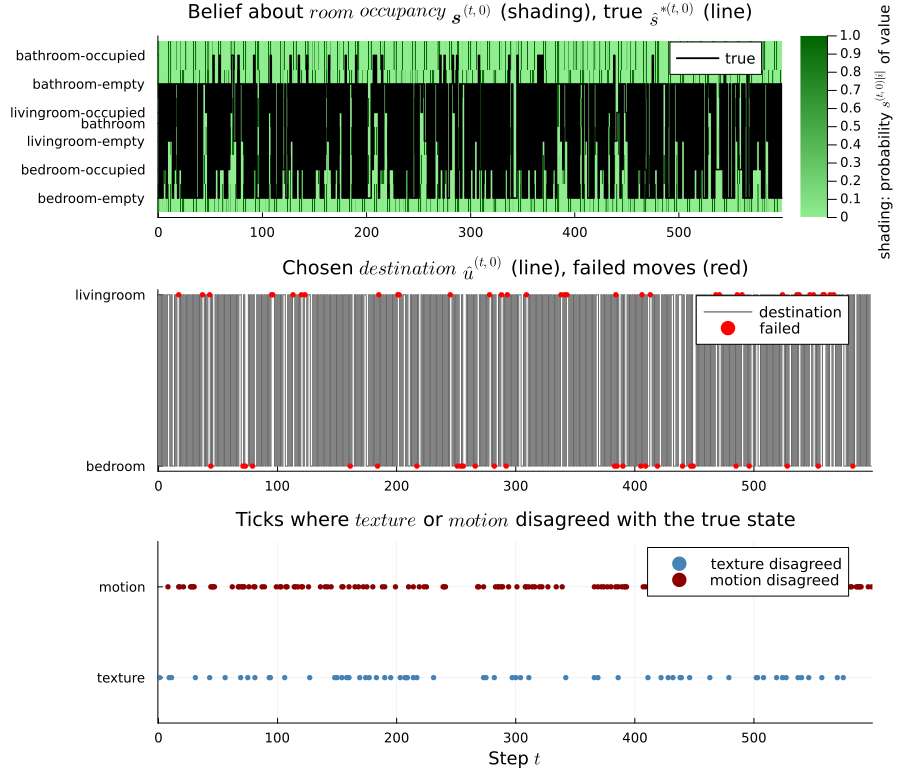

In [51]:
Lqsː = Lsː    ## the agent's beliefs s^{(t,0)}, t = 0, ..., T (0-based; recorded during the run)

## from joint states to room and occupancy (state order: room by room, empty before occupied)
room_of(p) = [p[1]+p[2], p[3]+p[4], p[5]+p[6]]    ## marginal over rooms
occ_of(p)  = p[2] + p[4] + p[6]                    ## probability that the room is occupied

true_states    = [argmax(Lŝˣ[roomoccupancy_n]) for Lŝˣ in parent(Lŝˣː)]    ## true joint state index 1..6
rooms          = (true_states .+ 1) .÷ 2                      ## true room: 1 bedroom, 2 livingroom, 3 bathroom
true_occupied  = iseven.(true_states)                         ## true occupancy

q_states       = [Ls[roomoccupancy_n] for Ls in parent(Lqsː)]               ## the agent's belief over the 6 joint states
inferred_rooms = [argmax(room_of(p)) for p in q_states]       ## most probable room
p_occupied     = [occ_of(p) for p in q_states]                ## agent's probability that the room is occupied
inferred_occ   = p_occupied .> 0.5

## ---------- behavior: disturbance and coverage (4.3.5) ----------
disturbance = mean(true_occupied)
coverage    = [mean(rooms .== r) for r in 1:3]
println("disturbance: agent $(round(100*disturbance, digits=1))%, random Roomba $(round(100*disturbance_random, digits=1))%")
println("coverage (bedroom, livingroom, bathroom): agent ", round.(100 .* coverage, digits=1),
        "%, random Roomba ", round.(100 .* coverage_random, digits=1), "%")

## ---------- tracking ----------
accuracy_room = mean(inferred_rooms .== rooms)
accuracy_occ  = mean(inferred_occ .== true_occupied)

textures           = [argmax(Lô[texture_m]) for Lô in parent(Lôː)]
camera_wrong       = textures .!= rooms
accuracy_cam_wrong = mean(inferred_rooms[camera_wrong] .== rooms[camera_wrong])
println("camera misread the floor at $(count(camera_wrong)) of $(T+1) ticks; ",
        "agent still inferred the right room at $(round(100*accuracy_cam_wrong, digits=1))% of those")

motion_detected    = [argmax(Lô[motion_m]) for Lô in parent(Lôː)] .== 2
motion_wrong       = motion_detected .!= true_occupied
accuracy_mot_wrong = mean(inferred_occ[motion_wrong] .== true_occupied[motion_wrong])
println("motion sensor was wrong at $(count(motion_wrong)) of $(T+1) ticks; ",
        "agent still inferred the right occupancy at $(round(100*accuracy_mot_wrong, digits=1))% of those")

## ---------- one run, stacked: belief, action, rare readings ----------
## z[t+1, i] is the belief of value i at tick t. heatmap(x, y, z) reads the first dimension as x.
nT = T + 1
belief = reduce(hcat, (collect(Ls[roomoccupancy_n]) for Ls in Lsː))    ## 6 × (T+1)
z_belief = permutedims(belief)                                           ## (T+1) × 6
true_y = Float64.(true_states)

p_bel = heatmap(0:T, 1:6, z_belief,
    c=:greens, clims=(0, 1), colorbar=:bottom,
    colorbar_title="shading: probability \$s^{(t,0)[i]}\$ of value \$i\$",
    title="Belief about \$\\mathit{room}\$ \$\\mathit{occupancy}\$ \$\\mathbf{\\mathit{s}}^{(t,0)}\$ (shading), true \$\\hat{s}^{\\ast(t,0)}\$ (line)",
    yticks=(1:6, state_labels),
    xlims=(-0.5, T + 0.5),
    legend=:topright)
plot!(p_bel, step_x(nT), step_y(true_y), color=:black, lw=1.5, label="true",
    linetype=:steppost)

## a red dot: the room at t+1 is not the room the destination was aiming at (the bathroom, when the far room was requested)
destinations_ai = [argmax(Lû[destination_n]) for Lû in parent(Lûː)]
failed = [rooms[t + 1] != next_room(rooms[t], destinations_ai[t]) for t in 1:T]
p_act = plot(step_x(T), step_y(Float64.(destinations_ai)), linetype=:steppost, color=:gray40,
    label="destination",
    title="Chosen \$\\mathit{destination}\$ \$\\hat{u}^{(t,0)}\$ (line), failed moves (red)",
    yticks=(1:3, action_labels),
    xlims=(-0.5, T + 0.5),
    legend=:topright)
scatter!(p_act, (0:T-1)[failed], destinations_ai[failed],
    color=:red, markersize=3, markerstrokewidth=0, label="failed")

cam_err = textures .!= rooms
mot_err = (motions .== 2) .!= true_occupied
p_rare = scatter(findall(cam_err) .- 1, fill(1, count(cam_err)),
    color=:steelblue, markersize=3, markerstrokewidth=0, label="texture disagreed",
    title="Ticks where \$\\mathit{texture}\$ or \$\\mathit{motion}\$ disagreed with the true state",
    yticks=(1:2, ["texture", "motion"]),
    ylims=(0.5, 2.5),
    xlims=(-0.5, T + 0.5),
    xlabel="Step \$t\$",
    legend=:topright)
scatter!(p_rare, findall(mot_err) .- 1, fill(2, count(mot_err)),
    color=:darkred, markersize=3, markerstrokewidth=0, label="motion disagreed")

plot(p_bel, p_act, p_rare, layout=(3, 1), size=(900, 780), link=:x)

In the plot above, look for three things.

The shading should follow the black step. Where it does, the most probable value of *room occupancy* is the true one, which is what $J_{\text{room}}$ and $J_{\text{occ}}$ summarize for this run.

A red dot is a tick whose *destination* did not produce the room it was aiming at. Aiming at the living room from the bedroom aims at the bathroom first, because that is the only door, so a successful trip through the bathroom is not a red dot.

The dots on the bottom panel are the ticks where *texture* or *motion* disagreed with the true room or the true occupancy. On this run the occupancy belief follows *motion* even when that reading is the wrong one.

In [52]:
## ---------- comparison over 30 seeds ----------
## The detail run above keeps seed 42 and, for its random reference, MersenneTwister(7).
## Here the environment uses the seed, and a random destination uses MersenneTwister(seed + 1000).

room_of(p) = [p[1] + p[2], p[3] + p[4], p[5] + p[6]]
occ_of(p)  = p[2] + p[4] + p[6]

function run_fixed(seed, next_u)
    L0 = tuple0([1.0, 0.0, 0.0, 0.0, 0.0, 0.0])
    (execute, observe, state) = create_envir(; LAˣ, LBˣ, Lŝˣ₀=L0, seed)
    states = Int[]
    u = 0
    for t = 0:T
        t > 0 && execute(tuple0(Float64.(1:3 .== u)))
        push!(states, argmax(state()[roomoccupancy_n]))
        t < T && (u = next_u(t))
    end
    states
end

function run_agent_seed(seed)
    L0 = tuple0([1.0, 0.0, 0.0, 0.0, 0.0, 0.0])
    (execute, observe, state) = create_envir(; LAˣ, LBˣ, Lŝˣ₀=L0, seed)
    (compute, act, future, slide, belief, scores) = create_agent()
    states = Int[]
    hit_room = 0
    hit_occ = 0
    n_mot = 0
    n_mot_wrong_belief = 0
    prev = nothing
    for t = 0:T
        t > 0 && execute(prev)
        s_idx = argmax(state()[roomoccupancy_n])
        push!(states, s_idx)
        Lôₜ = observe()
        compute(Lôₜ)
        bel = belief()[roomoccupancy_n]
        room = (s_idx + 1) ÷ 2
        occ = iseven(s_idx)
        hit_room += argmax(room_of(bel)) == room
        hit_occ += (occ_of(bel) > 0.5) == occ
        mot_says = argmax(Lôₜ[motion_m]) == 2
        if mot_says != occ
            n_mot += 1
            n_mot_wrong_belief += (occ_of(bel) > 0.5) != occ
        end
        if t < T
            prev = act()
            slide()
        end
    end
    disturb = mean(iseven.(states))
    rooms = (states .+ 1) .÷ 2
    cover = [mean(rooms .== r) for r in 1:3]
    (; disturb, cover, room=hit_room / (T + 1), occ=hit_occ / (T + 1),
       mot_follow = n_mot == 0 ? 1.0 : n_mot_wrong_belief / n_mot)
end

function mean_cover(xs)
    c = reduce(hcat, [x.cover for x in xs])
    vec(mean(c, dims=2))
end

seeds = 1:30
agent_runs = [run_agent_seed(seed) for seed in seeds]
rand_states = map(seeds) do seed
    rng = MersenneTwister(seed + 1000)    ## one stream for the whole run; a new generator each tick would reset it
    run_fixed(seed, t -> rand(rng, 1:3))
end
bed_states  = [run_fixed(seed, t -> 1) for seed in seeds]
liv_states  = [run_fixed(seed, t -> 2) for seed in seeds]
bath_states = [run_fixed(seed, t -> 3) for seed in seeds]

pct(x) = round(100 * x, digits=1)
function covers(list)
    mats = [[mean(((s .+ 1) .÷ 2) .== r) for r in 1:3] for s in list]
    pct.(vec(mean(reduce(hcat, mats), dims=2)))
end
disturbs(list) = pct(mean(mean(iseven.(s)) for s in list))

println("over $(length(seeds)) seeds")
println("agent            disturbance $(pct(mean(r.disturb for r in agent_runs)))%   coverage ", pct.(mean_cover(agent_runs)))
println("random+1000      disturbance $(disturbs(rand_states))%   coverage ", covers(rand_states))
println("always bedroom   disturbance $(disturbs(bed_states))%   coverage ", covers(bed_states))
println("always livingroom disturbance $(disturbs(liv_states))%   coverage ", covers(liv_states))
println("always bathroom  disturbance $(disturbs(bath_states))%   coverage ", covers(bath_states))
println("agent tracking   room $(pct(mean(r.room for r in agent_runs)))%   occupancy $(pct(mean(r.occ for r in agent_runs)))%")
println("agent disturbance range $(pct(minimum(r.disturb for r in agent_runs)))% to $(pct(maximum(r.disturb for r in agent_runs)))%")
println("living-room share under 15% on $(count(r -> r.cover[2] < 0.15, agent_runs)) of $(length(seeds)) seeds")
println("motion-error ticks on which the occupancy belief is also wrong: $(pct(mean(r.mot_follow for r in agent_runs)))%")

over 30 seeds
agent            disturbance 21.9%   coverage [43.2, 7.2, 49.7]
random+1000      disturbance 25.7%   coverage [25.5, 24.0, 50.5]
always bedroom   disturbance 32.4%   coverage [100.0, 0.0, 0.0]
always livingroom disturbance 32.8%   coverage [0.2, 99.6, 0.2]
always bathroom  disturbance 32.4%   coverage [0.2, 0.0, 99.8]
agent tracking   room 94.6%   occupancy 92.1%
agent disturbance range 18.5% to 24.8%
living-room share under 15% on 30 of 30 seeds
motion-error ticks on which the occupancy belief is also wrong: 99.9%


### 4.7 Conclusion and outlook

The agent chose, at every tick, the *destination* of the Roomba. It observed *texture*, *light* and *motion*, and it had to infer *room occupancy*, which it never sees. It then picked the policy with the lower expected free energy and carried out that policy's first action. Four ingredients shaped what happened:

- **Action-dependent transitions.** $\boldsymbol{B}^{(0)}$ has one matrix per *destination*, including moves that fail and the detour through the bathroom.
- **A preference over *motion*.** The goal is $\log\boldsymbol{C}^{(2)}$, a preference for "no motion", because occupancy itself is hidden.
- **Planning by expected free energy.** For each of the $3^{2} = 9$ policies the agent predicts the next two ticks and scores them by $G_{\Sigma}^{[p]}$.
- **An online loop.** `compute`, `act`, `future` and `slide` now run one tick at a time, against `execute`, `observe` and `state`.

The question of this part is whether a preference for "no motion" keeps the Roomba out of occupied rooms without abandoning the apartment.

**Over 30 seeds the agent disturbs less than a random Roomba, and less than any fixed destination.** Mean disturbance, 600 ticks, seeds $1$ through $30$: the agent $21.9\%$, random *destination* $25.7\%$, always "bedroom" $32.4\%$, always "livingroom" $32.8\%$, always "bathroom" $32.4\%$. Room tracking averaged $94.6\%$, occupancy tracking $92.1\%$.

| strategy | disturbance | bedroom | living room | bathroom | room tracking | occupancy tracking |
|---|---|---|---|---|---|---|
| always "bedroom" | 32.4% | 100% | 0% | 0% | — | — |
| always "livingroom" | 32.8% | 0.2% | 99.6% | 0.2% | — | — |
| always "bathroom" | 32.4% | 0.2% | 0% | 99.8% | — | — |
| random *destination* | 25.7% | 25.5% | 24.0% | 50.5% | — | — |
| agent | 21.9% | 43.2% | 7.2% | 49.7% | 94.6% | 92.1% |

**The agent avoids the living room on every one of the 30 seeds.** Its share of that room averaged $7.2\%$, against $24.0\%$ for the random *destination*, and on every seed the share was under $15\%$. The living room is the room with $p_{\text{occ}} = 0.5$. The bathroom, with $p_{\text{occ}} = 0.1$, took about half the ticks, and it is also the passage between the other two rooms. Always heading for the bathroom does not win: its disturbance is $32.4\%$, because the bathroom's own occupancy, once the Roomba has settled there, is not zero.

**On the detail run the occupancy belief followed *motion*, including the wrong readings.** Seed 42, the run drawn above: disturbance $17.3\%$ against $27.2\%$ for the random Roomba on that same environment stream, coverage $44.3\%$, $6.3\%$, $49.3\%$ against $23.7\%$, $28.0\%$, $48.3\%$. Room tracking was $95.8\%$. The camera was wrong on 63 ticks, and the agent still had the room right on $65.1\%$ of those, because the room carries over from the previous tick. The modality *motion* was wrong on 38 ticks, and the occupancy belief was wrong on every one of them. Over the 30 seeds the agent was wrong on $99.9\%$ of the ticks where *motion* was wrong. Staying would have given a second reading; the agent usually moved, and a room entered fresh has no history, so one reading decides. In the bathroom a false alarm moves the probability of occupied from $0.1$ to about $0.64$.

**Nothing in the preference asks the Roomba to clean.** The living room is the room most often occupied, and it is also the room a cleaner would most need to visit. Avoiding people and covering the apartment are two goals. The agent has one of them.

**Caveats.** The detail run flatters the agent. Across seeds $1$ through $30$ its disturbance ranged from $18.5\%$ to $24.8\%$, mean $21.9\%$, so the $17.3\%$ of seed 42 is a low draw, and the gap against the random Roomba on that one stream ($17.3$ against $27.2$) is wider than the gap of the means ($21.9$ against $25.7$). The probabilities $p_{\text{move}}$, $p_{\text{occ}}$, $p_{\text{stay}}$ and the sensor columns are assumed. A room whose occupancy flipped faster, or a sensor that missed people more often, would move these percentages. The fixed-destination baselines never clean more than one room, so beating them on disturbance is a weak compliment; the random *destination* is the baseline that still covers the apartment.

**Possible next steps.**

- **A cleaning goal.** A state factor for how dirty each room is, growing over time and reset by cleaning, plus a preference for clean rooms, would pull the agent into the living room when it is quiet.
- **A second look.** Staying one more tick would give another *motion* reading. A longer horizon, or a heavier weight on ambiguity, may make that worth doing.
- **Learning while acting.** The matrices were given. Learning $\mathbf{A}$ and $\mathbf{B}$ while acting brings back the trade-off between exploring and using what is already known.
- **The preference and the horizon.** $H$ and $\log\boldsymbol{C}^{(2)}$ were not swept. The 30-seed comparison above is the right way to judge a sweep.
- **Planning as inference.** For a larger model, evaluating all $3^{H}$ policies explicitly stops being cheap, and `RxInfer` is the natural next tool.

The Roomba now chooses to avoid company. The next step is to make it want to clean as well.

## APPENDIX A: Text conventions and their motivation

Three styles, each with one role. Italic lower case is the name of a model variable, at every occurrence, including in headings: *room occupancy*, *texture*, *light*, *motion*, *destination*. Double quotes are a value of such a variable, and they match the label strings, so a search for "no motion" finds the value in the text and in `motion_labels`. Bold is a low-level heading or a label. Backticks are code. Italics, bold and capitals are not used for emphasis, and the notebook does not use underlining.

A name is written in lower case so that it reads as an identifier, including where a sentence would otherwise start with it. The words of a name are separated by spaces, not hyphens or underscores. A new domain term is introduced under **Terms added in this part**, or defined in the sentence, and is not set in italics for being new.

The same word without italics has its everyday meaning. The modality *light* is the sensor; brightness is the physical quantity it measures. The modality *motion* is the sensor; movement is what a person does. The factor is *room occupancy*, one name, so that "room" and "occupied" can stay ordinary words. The control factor is *destination*; "the room it heads for" is the everyday description. These names share no word with each other, and none of them is also a metric. Disturbance, coverage and tracking are metrics, with symbols $J_{\text{disturb}}$, $J_{\text{cover}}$ and $J_{\text{room}}$, $J_{\text{occ}}$.

Part 3 called the state factor `RoomOccupancy` and the modalities `Texture`, `Light` and `Motion`. This part writes them as the italic names above. The values were already the label strings.

The reason for keeping the styles apart is that the domain and the model share words. If italics also meant emphasis, or a value, a reader could not tell *motion* the modality from a stressed use of the ordinary word. Appendix B records the modeling choices for the same kind of reason: so they are not undone by accident.

## APPENDIX B: Modeling choices and assumptions, and their motivation

**One factor for room and occupancy.** Two factors would need a transition in which the next occupancy depends on whether the room changed. A single factor with six values states that dependence directly: on a move, the next occupancy is drawn from $p_{\text{occ}}$ of the room just entered, and it does not depend on the room just left. The cost is a $6 \times 6 \times 3$ array instead of two smaller ones.

**No door between the bedroom and the living room.** A request for the far room first aims at the bathroom, with success probability $p_{\text{move}} = 0.9$. The bathroom is therefore both the quietest room and the hallway. Coverage of the bathroom is partly passage, not only a preference for it.

**The numbers are assumed.** $p_{\text{move}} = 0.9$. While the Roomba stays, an empty room stays empty with probability $0.95$ and an occupied room stays occupied with probability $0.9$. On entry, $p_{\text{occ}}$ is $0.3$ for the bedroom, $0.5$ for the living room and $0.1$ for the bathroom. The camera misreads the floor with probability $0.1$, split equally. The modality *light* is uninformative in the bedroom ($0.5$), usually "high" in the living room ($0.85$) and usually "low" in the bathroom ($0.9$). The modality *motion* reports "motion" with probability $0.8$ when occupied and $0.05$ when empty. None of these were measured on a Roomba. When measured numbers arrive, 4.3.4 is the place they replace.

**The agent is given $\mathbf{A}$ and $\mathbf{B}$.** Part 3 learned the observation matrices. This part hands them over, equal to the environment's, so that a mistake in control is not confused with a mistake in learning. The agent does not know the initial state: $\boldsymbol{D}^{(0)}$ is uniform, while the Roomba starts at "bedroom-empty".

**Perception is exact.** One factor and known matrices, so the belief update is Bayesian filtering, not a mean-field approximation. There is no variational free energy to plot.

**$\log\boldsymbol{C}$ is given directly.** The modalities *texture* and *light* are for perception only, so $\log\boldsymbol{C}^{(0)} = \log\boldsymbol{C}^{(1)} = \boldsymbol{0}$. For *motion*, $\log\boldsymbol{C}^{(2)} = \log(0.9, 0.1)$. Normalizing those two weights into a distribution, and then taking the logarithm, would add the same constant to every $G_{\Sigma}^{[p]}$ and would change no decision. Setting the flat modalities to $\boldsymbol{0}$ rather than to $\log$ of a uniform vector also changes $G_{\Sigma}^{[p]}$ by a constant only. The actions of the detail run match the previous version of this notebook, which stored the weights as a distribution and took the logarithm inside the score.

**No cost of effort.** There is no habit vector $\boldsymbol{E}$. Every policy is a priori equal apart from its expected free energy. A penalty for moving would be a later addition, and it would need a symbol that is not already a metric.

**Horizon $H = 2$.** Nine policies, scored exhaustively. A longer horizon sees further and costs $3^{H}$ policies. The predictions along policies that share a first step are not cached; the result would be the same if they were.

**The detail run keeps its original random streams.** The environment uses seed 42. The random Roomba of the detail run draws destinations from `MersenneTwister(7)`, which is the stream the previous version used, so that run's trajectory is unchanged. The 30-seed comparison follows the series protocol: the environment uses the seed, and the random *destination* uses `MersenneTwister(seed + 1000)`. Seeds $1$ through $30$.

**What was left out.** A second state factor for dirt. A preference that rewards visiting every room. Learning $\mathbf{A}$ and $\mathbf{B}$ while acting. A precision on the policy posterior other than the plain softmax. Doors that are sometimes shut. Those are the next steps in 4.7, not omissions in the code.